# DF40: native stills и композитные сплиты

EDA для бинарного детектора дипфейков. Берём до 100 000 изображений из native EFS + FE: генерацию лица целиком и редактирование лица. FS/FR и самостоятельные real-кадры FF++ / Celeb-DF в этот сабсет не входят. Результаты инверсии и редактирования остаются изображениями результата метода.

Ноутбук сначала проверяет выборку DF40, затем собирает и проверяет общий `train / validate / test` из DF40, OpenForensics, 140k real and fake и MFFI. Все числа и изображения ниже читаются из полученных данных.

## 1. Как воспроизвести

Запускаем из корня репозитория. Общая среда использует Python 3.11; точные зависимости находятся в `environment.yml`. Скачивание выполняем на виртуалке до запуска EDA. Ноутбук не запускает повторную загрузку сотен гигабайт.

```bash
bash scripts/setup_environment.sh
source "$HOME/miniconda3/etc/profile.d/conda.sh"
conda activate deepfake-eda
bash scripts/download_models.sh
python scripts/download_df40.py --root "${DEEPFAKE_DATA_ROOT:-data/raw}/df40" --max-images 100000 --seed 42
bash scripts/download_datasets.sh --datasets 140k mffi openforensics --limit 20000 --seed 42

python scripts/index_datasets.py --dataset 140k --limit 20000 --seed 42 --output data/processed/manifests/140k.jsonl
python scripts/index_datasets.py --dataset openforensics --limit 20000 --seed 42 --output data/processed/manifests/openforensics.jsonl
python scripts/index_datasets.py --dataset mffi --limit 20000 --seed 42 --output data/processed/manifests/mffi.jsonl

python scripts/preprocess.py --manifest "${DEEPFAKE_DATA_ROOT:-data/raw}/df40/sample.parquet" --output-dir data/processed/df40 --workers 4 --crop-policy adaptive
python scripts/preprocess.py --manifest data/processed/manifests/140k.jsonl --output-dir data/processed/140k --workers 4 --crop-policy adaptive
python scripts/preprocess.py --manifest data/processed/manifests/openforensics.jsonl --output-dir data/processed/openforensics --workers 4 --crop-policy adaptive
python scripts/preprocess.py --manifest data/processed/manifests/mffi.jsonl --output-dir data/processed/mffi --workers 4 --crop-policy adaptive
python scripts/preprocess.py --output-dir data/processed/df40 --quality-only --min-mask-fraction 0.25
python scripts/preprocess.py --output-dir data/processed/140k --quality-only --min-mask-fraction 0.25
python scripts/preprocess.py --output-dir data/processed/openforensics --quality-only --min-mask-fraction 0.25
python scripts/preprocess.py --output-dir data/processed/mffi --quality-only --min-mask-fraction 0.25
python scripts/build_composite_splits.py --manifest data/processed/df40/metadata.parquet data/processed/140k/metadata.parquet data/processed/openforensics/metadata.parquet data/processed/mffi/metadata.parquet --output data/splits/composite --config configs/composite.yml --split-policy global_balanced --group-cache data/processed/verified_groups
bash scripts/start_jupyter.sh
```

`preprocess.py` возобновляет расчёт через SQLite checkpoint. Он проверяет байты исходника, параметры, версии кода, хеши моделей и сохранённых кропов. Повторный запуск использует только совместимые результаты. Ядро ноутбука: `Python (deepfake EDA)`.

При заданном DEEPFAKE_DATA_ROOT исходники читаются из этого каталога. Модели, результаты препроцессинга и итоговые сплиты остаются в структуре репозитория.

quality-only применяет фильтр по уже измеренной доле маски без повторного детектора/landmarker и без перезаписи изображений.

После удаления raw-файлов и кропов повторно строим сплиты по сохранённым metadata. Для этого нужны четыре data/processed/*/metadata.parquet с аудитами, acquisition snapshot и проверенный group cache. Inference повторно не запускаем. Три pixel-панели ниже берём из проверенного прошлого реального прогона: это отдельно помеченные иллюстрации с SHA256 provenance. Остальные таблицы, графики и новый split считаются заново.

Режим полного прогона использует команды выше. Режим повторной сборки по retained metadata запускает этот ноутбук с сохранёнными артефактами. Свежий clone без датасетов и metadata сначала требует полный прогон. Если raw/crops доступны, pixel-панели обновляются непосредственно по пикселям.

Свежий полный pipeline можно выполнить через `bash scripts/prepare_composite.sh --group-cache data/processed/verified_groups`. Этот mutable cache создаётся по реально доступным пикселям и остаётся в ignored data/processed.

Для повторной сборки текущих сохранённых metadata после cleanup используется проверенный shipped cache:

```bash
python scripts/build_composite_splits.py --manifest data/processed/df40/metadata.parquet data/processed/140k/metadata.parquet data/processed/openforensics/metadata.parquet data/processed/mffi/metadata.parquet --output data/splits/composite --config configs/composite.yml --split-policy global_balanced --group-cache data/group_cache/verified_groups
```

Ноутбук предпочитает data/processed/verified_groups, если там уже есть manifest.json; иначе использует shipped cache. Cache привязан к входным metadata и логике проверки. При несовпадении fingerprint запуск завершается ошибкой. После изменения входов нужно вернуть изображения и построить новый cache по пикселям; старые связи автоматически не переносятся.

In [1]:
import importlib.metadata as metadata
import json
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Image, Markdown, display

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "environment.yml").is_file() and (path / "src/preprocessing").is_dir()
)
sys.path.insert(0, str(ROOT))
from src.notebook_src import df40_eda as E

E.style()
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
versions = pd.DataFrame({
    "пакет": ["Python", "numpy", "pandas", "opencv-contrib-python", "mediapipe", "matplotlib", "pyarrow"],
    "версия": [sys.version.split()[0]] + [
        metadata.version(name)
        for name in ["numpy", "pandas", "opencv-contrib-python", "mediapipe", "matplotlib", "pyarrow"]
    ],
})
display(versions.set_index("пакет"))

,версия
пакет,
Python,3.11.18
numpy,1.26.4
pandas,2.2.3
opencv-contrib-python,4.11.0.86
mediapipe,0.10.21
matplotlib,3.9.2
pyarrow,18.1.0


## 2. Что именно выбрали и как свели таргет

Единица семплирования DF40 - опубликованное изображение. Исходная многоклассовая информация о методе остаётся в `generator / native_method / manipulation`; бинарный таргет задаём отдельно: `0 = real`, `1 = fake`. Название метода не становится отдельным классом детектора.

Выборка пропорциональна доступным стратам: метод, таргет, тип манипуляции, домен, авторский сплит и исходный формат. Используем largest remainder и фиксированный seed. Размер ограничен 100k; если изображений меньше, берём все. Баланс real/fake сохраняет пропорции этого native-инвентаря, поэтому 50/50 здесь не навязываем.

Формат в полном инвентаре определяется по расширению. После скачивания препроцессор проверяет реальный формат по заголовку. Поза и свет до измерения неизвестны; равенство их распределения с полным DF40 не утверждаем.

Для авторской части DF40 используем общий протокол `DF40_all.json`: точное совпадение пути имеет приоритет над частью архива. Если путь не найден в общем JSON, сохраняем опубликованную train/test-часть архива. Отдельные JSON с holdout конкретных методов задают другой эксперимент; с общим протоколом их не смешиваем. Поэтому архив с названием Test иногда содержит строки author train, если это явно задано общим JSON.

native_family хранит исходную семью архива EFS/FE. Это происхождение, а не метка подделки: для настоящих изображений manipulation = real, для fake - EFS или FE. native_method сохраняем у обоих классов, чтобы видеть баланс каждого источника.

Авторский протокол здесь описывает provenance исходника. В финальном global_balanced его части не ограничивают распределение строк.

In [2]:
inventory, sample, faces, sampling, preprocessing_audit = E.load_df40(ROOT)
assert len(sample) <= 100_000
assert sample["sample_id"].is_unique
assert set(sample["sample_id"]) <= set(inventory["sample_id"])
assert inventory["target"].isin([0, 1]).all()
assert sample["target"].isin([0, 1]).all()
assert set(inventory.loc[inventory["target"].eq(1), "manipulation"].dropna()) <= {"EFS", "FE"}
assert inventory.loc[inventory["target"].eq(0), "manipulation"].eq("real").all()
if "native_family" in inventory:
    assert set(inventory["native_family"].dropna()) <= {"EFS", "FE"}
real_domains = set(inventory.loc[inventory["target"].eq(0), "domain"].dropna().str.lower())
assert real_domains <= {"ffhq", "celeba"}

display(E.stage_table(inventory, sample, faces))
fake_share = sample["target"].eq(1).mean()
display(Markdown(
    f"В native-инвентаре **{len(inventory):,}** изображений; "
    f"выбрано **{len(sample):,}**. Доля fake в сабсете - **{fake_share:.1%}**. "
    f"Обработка дала **{len(faces):,}** строк, включая записи об ошибках. "
    f"Сохранено **{int(faces['crop_path'].notna().sum()):,}** кропов; "
    f"**{int(faces['eligible'].sum()):,}** проходят первоначальные фильтры."
))
display(pd.Series({
    "seed": sampling.get("seed", 42),
    "изображений в выборке": len(sample),
    "native методов": inventory["native_method"].nunique(),
    "источник бинарного таргета": "проверенная разметка и native-структура DF40",
    "кропы": "lossless PNG, 256 × 256",
}, name="значение").to_frame())
if "author_metadata_status" in inventory:
    display(inventory["author_metadata_status"].value_counts().rename("изображений").to_frame())

,строк,real,fake,генераторов fake,записей bbox (face_index),сохранённых кропов,eligible
этап,,,,,,,
Инвентарь native stills,619733,7984,611749,17,<NA>,<NA>,<NA>
Выбранные изображения,100000,1287,98713,17,<NA>,<NA>,<NA>
Строки обработки (включая ошибки),100086,1288,98798,17,99317,99317,98020


В native-инвентаре **619,733** изображений; выбрано **100,000**. Доля fake в сабсете - **98.7%**. Обработка дала **100,086** строк, включая записи об ошибках. Сохранено **99,317** кропов; **98,020** проходят первоначальные фильтры.

,значение
seed,42
изображений в выборке,100000
native методов,17
источник бинарного таргета,проверенная разметка и native-структура DF40
кропы,"lossless PNG, 256 × 256"


,изображений
author_metadata_status,
archive_partition_only,591274
matched,28459


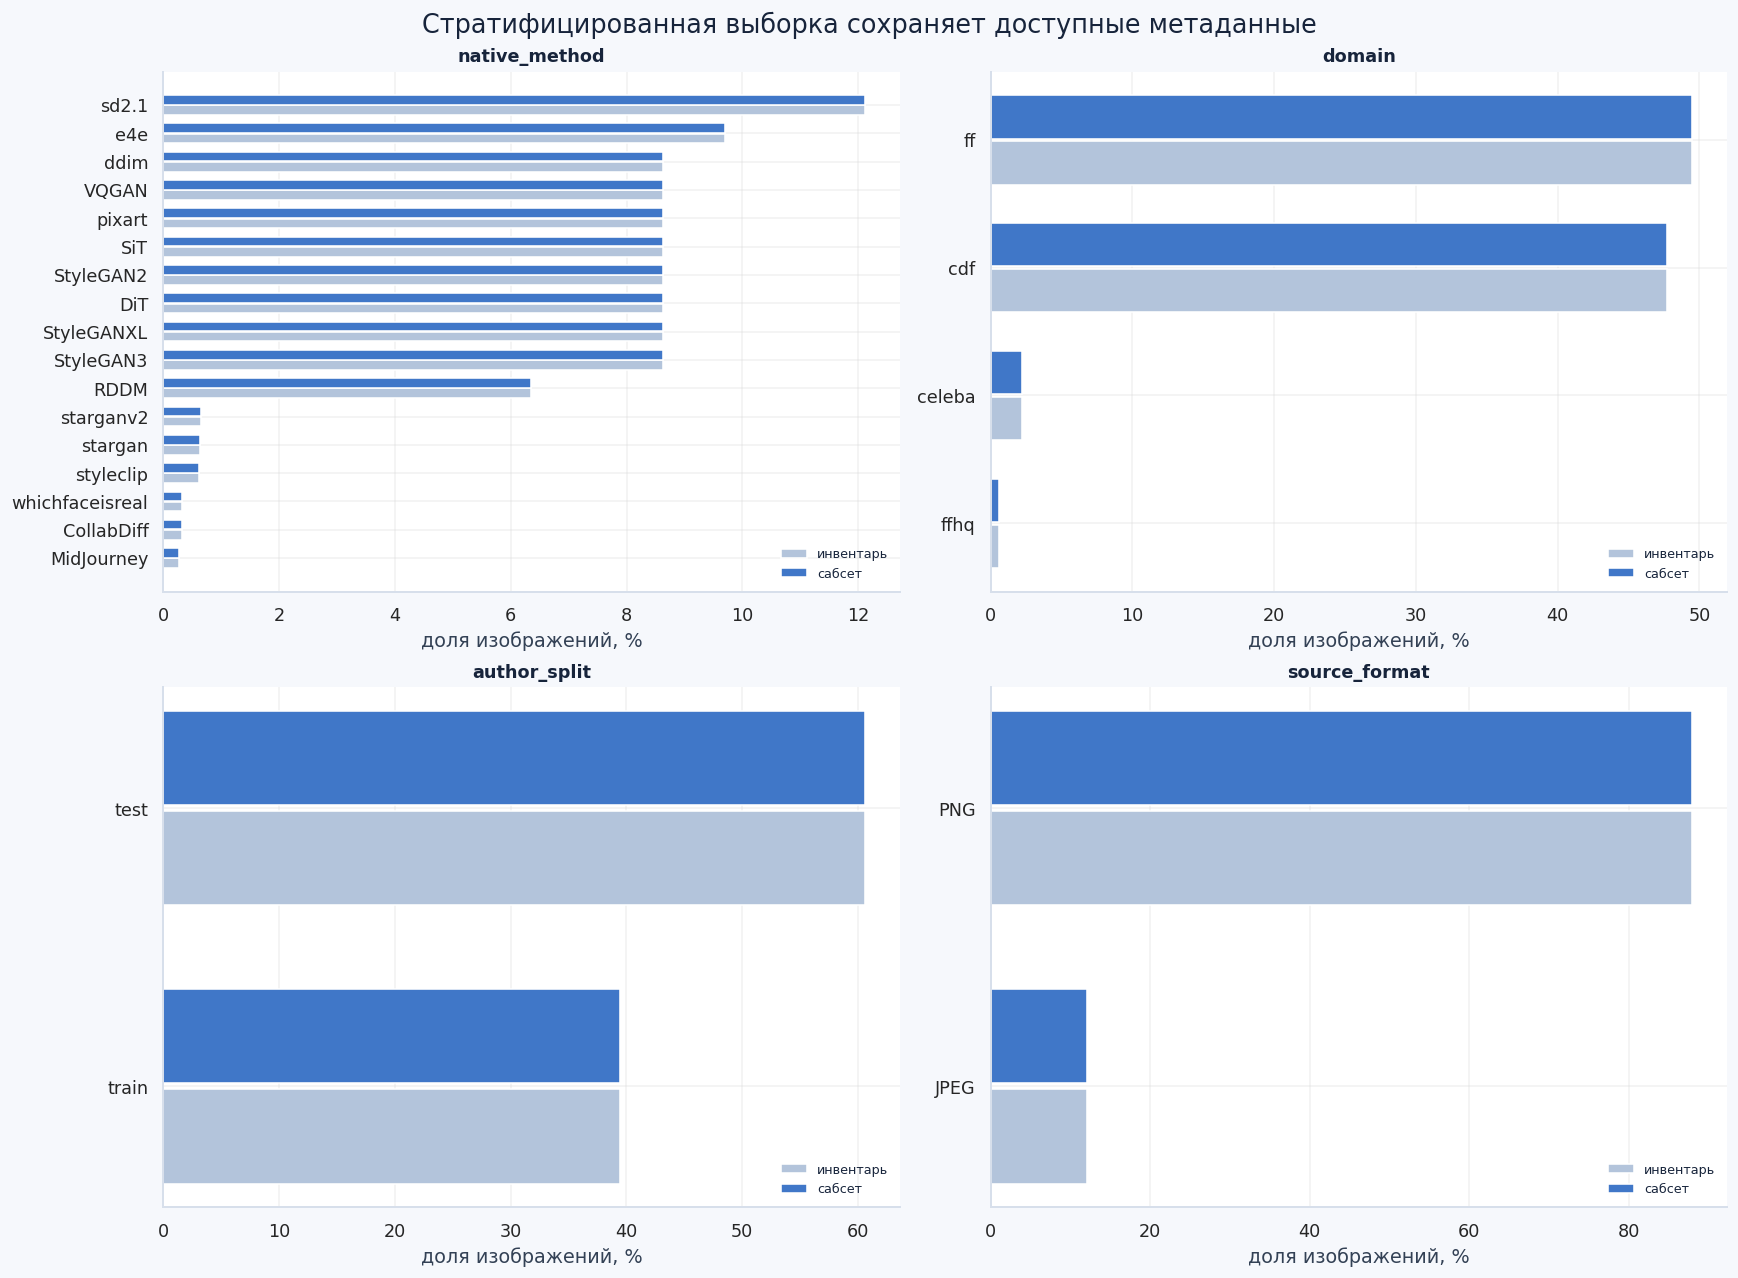

,TV,JS_bits,max_gap_pp
признак,,,
target,0.00001,0.000000,0.001
generator,0.00004,0.000000,0.001
native_method,0.00004,0.000000,0.001
native_family,0.00002,0.000000,0.002
manipulation,0.00003,0.000000,0.003
domain,0.00005,0.000000,0.005
author_split,0.00002,0.000000,0.002
source_format,0.00002,0.000000,0.002


In [3]:
E.plot_sampling(inventory, sample)
plt.show()
fidelity = E.sampling_fidelity(inventory, sample)
display(fidelity.style.format({"TV": "{:.5f}", "JS_bits": "{:.6f}", "max_gap_pp": "{:.3f}"}))

TV показывает, какая доля вероятностной массы различается между распределениями. JS измеряем в битах. Здесь сравниваем только признаки, которые доступны и для полного native-инвентаря, и для выборки.

,native_method,native_family,generator,manipulation,domain,target,изображений
25,sd2.1,EFS,sd2.1,EFS,ff,1,7566
2,DiT,EFS,DiT,EFS,cdf,1,4546
8,SiT,EFS,SiT,EFS,cdf,1,4546
10,StyleGAN2,EFS,StyleGAN2,EFS,cdf,1,4546
12,StyleGAN3,EFS,StyleGAN3,EFS,cdf,1,4546
14,StyleGANXL,EFS,StyleGANXL,EFS,cdf,1,4546
16,VQGAN,EFS,VQGAN,EFS,cdf,1,4546
18,ddim,EFS,ddim,EFS,cdf,1,4546
22,pixart,EFS,pixart,EFS,cdf,1,4546
24,sd2.1,EFS,sd2.1,EFS,cdf,1,4546


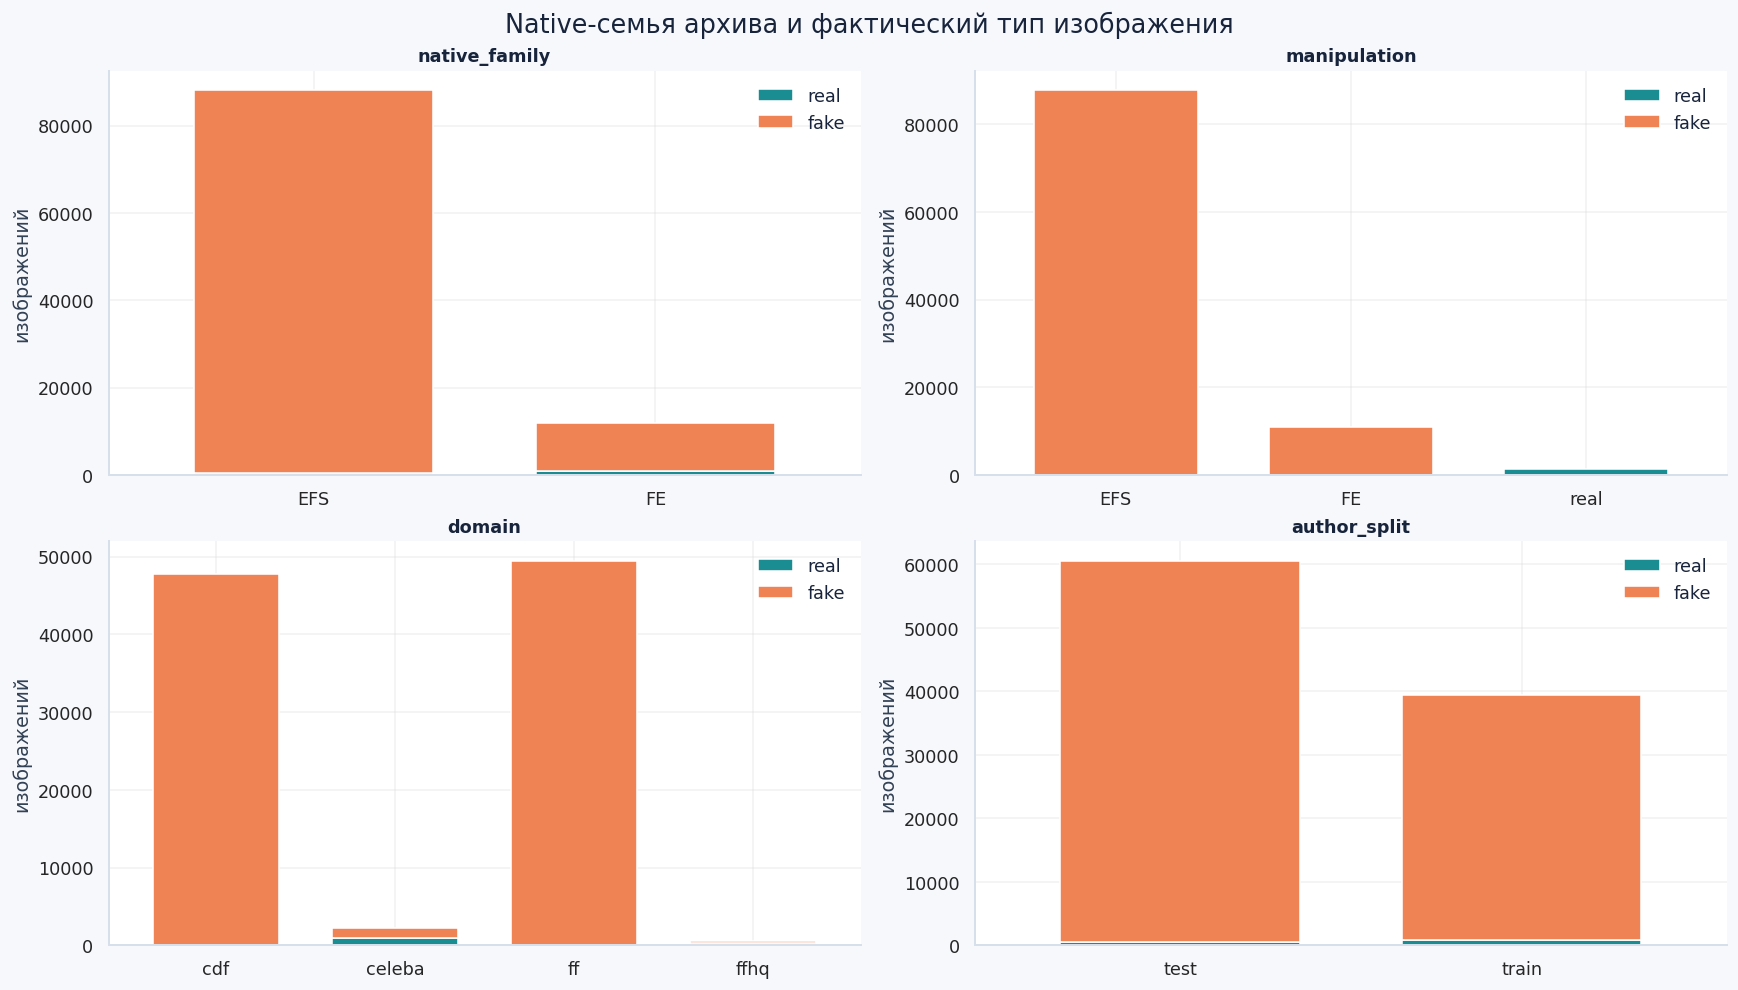

author_split,test,train
native_method,,
CollabDiff,1,321
DiT,5145,3484
MidJourney,0,263
RDDM,2862,3484
SiT,5145,3484
StyleGAN2,5145,3484
StyleGAN3,5145,3484
StyleGANXL,5145,3484
VQGAN,5145,3484


In [4]:
method_columns = ["native_method", "generator", "manipulation", "domain", "target"]
if "native_family" in sample:
    method_columns.insert(1, "native_family")
method_counts = (
    sample.groupby(method_columns, dropna=False)
    .size().rename("изображений").reset_index()
    .sort_values(["manipulation", "изображений"], ascending=[True, False])
)
display(method_counts)
E.plot_composition(sample)
plt.show()
display(pd.crosstab(sample["native_method"], sample["author_split"]).style.background_gradient(cmap="Blues"))

### Масштаб YuNet и фактическое покрытие

[OpenCV Zoo](https://github.com/opencv/opencv_zoo/blob/main/models/face_detection_yunet/README.md) указывает рабочий размер лиц примерно от 10 × 10 до 300 × 300 px. Поэтому для крупных лиц добавляем детекцию на уменьшенной копии.

Native-проход выполняется всегда, чтобы сохранить чувствительность к небольшим лицам от 32 px в исходнике. Если длинная сторона изображения больше 320 px, добавляем копию с длинной стороной 320. Bbox и пять ориентиров возвращаем в оригинальные координаты по фактическим коэффициентам ширины и высоты. Детекции объединяем NMS с IoU 0.3; порог confidence остаётся 0.9.

Копия используется только детектором. Adaptive-кропы вырезаются из оригинальных декодированных пикселей. Ниже сравниваем native и объединённое покрытие на тех же изображениях одного реального прогона, без обращения к старым результатам.

,input_images,measured_images,native_face_images,downscaled_face_images,merged_face_images,rescued_images,native_face_lost_images,native_coverage_all,merged_coverage_all
0,100000,100000,78354,31407,99231,20877,0,0.784,0.992


,input_images,measured_images,native_face_images,downscaled_face_images,merged_face_images,rescued_images,native_face_lost_images,native_coverage_all,merged_coverage_all
native_method,,,,,,,,,
CollabDiff,322,322,316,161,316,0,0,98.1%,98.1%
DiT,8629,8629,8617,0,8617,0,0,99.9%,99.9%
MidJourney,263,263,216,102,263,47,0,82.1%,100.0%
RDDM,6346,6346,5891,0,5891,0,0,92.8%,92.8%
SiT,8629,8629,8625,0,8625,0,0,100.0%,100.0%
StyleGAN2,8629,8629,8575,0,8575,0,0,99.4%,99.4%
StyleGAN3,8629,8629,8593,0,8593,0,0,99.6%,99.6%
StyleGANXL,8629,8629,8629,0,8629,0,0,100.0%,100.0%
VQGAN,8629,8629,8625,0,8625,0,0,100.0%,100.0%


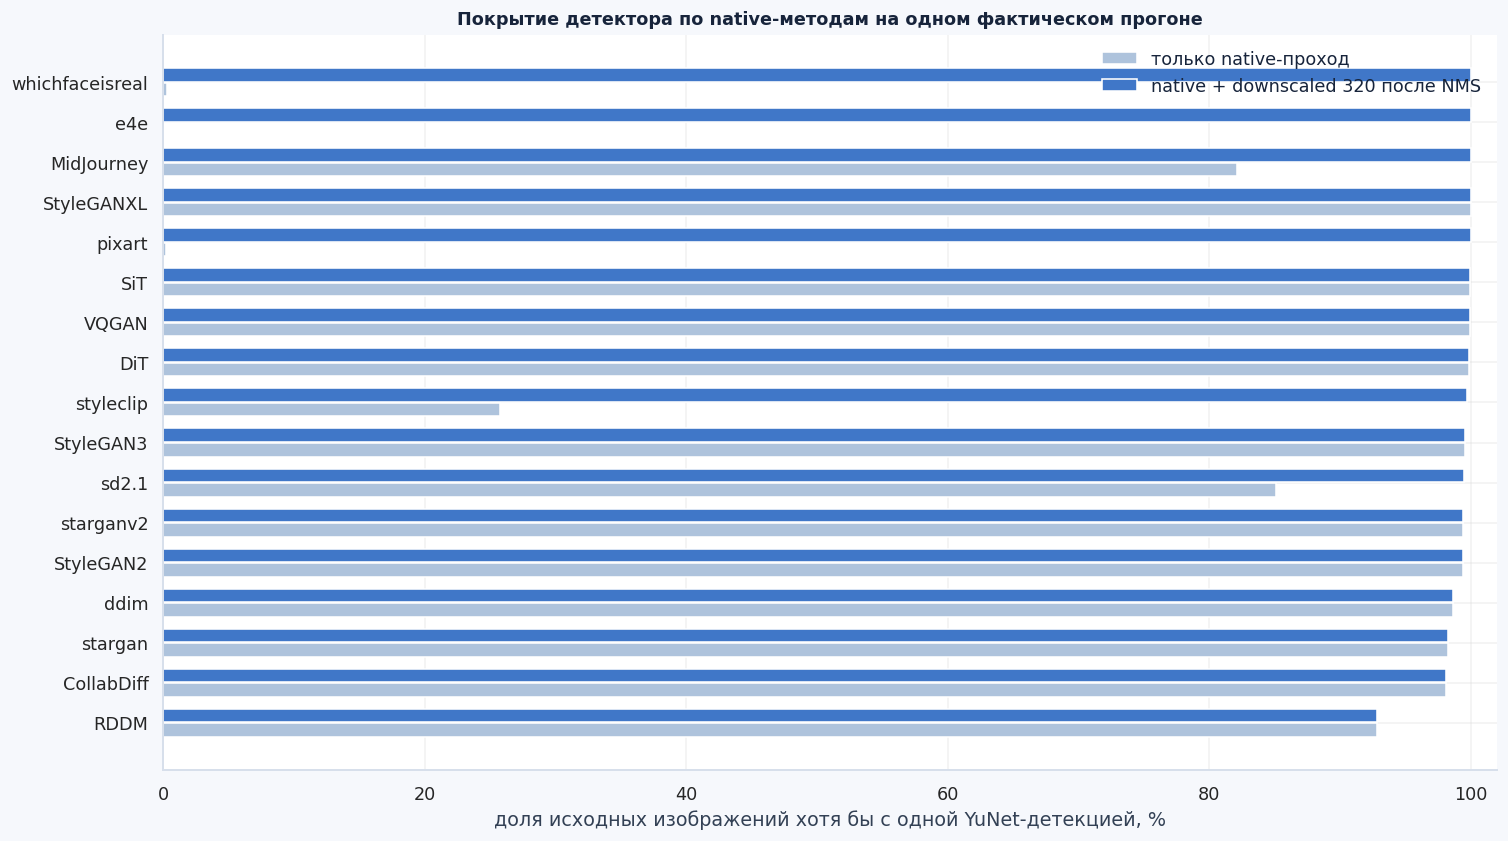

In [5]:
if "detector_policy" not in faces or not faces["detector_policy"].eq("native_plus_downscaled_320").all():
    raise ValueError("Нужен актуальный preprocess-прогон с native + downscaled 320")
detector_coverage = E.detector_coverage_summary(faces)
display(detector_coverage["overall"])
display(
    detector_coverage["by_native_method"].set_index("native_method")
    .style.format({"native_coverage_all": "{:.1%}", "merged_coverage_all": "{:.1%}"})
)
E.plot_detector_coverage(detector_coverage)
plt.show()
assert detector_coverage["overall"].iloc[0]["native_face_lost_images"] == 0

## 3. Как выглядят исходники и кропы

Во всех четырёх датасетах используем adaptive-квадрат с центром в центре bbox. Выбираем максимальную целую сторону, которая помещается в исходник и не превышает `1.3 × max(width, height)`:

`side = floor(min(1.3 × max(w, h), 2 × min(cx, cy, W-cx, H-cy)))`.

Пиксельные границы округляются с отклонением центра до 0.5 px. Фактический кроп целиком внутри изображения: padding не добавляется. Если допустимый коэффициент меньше 1, часть bbox может быть отрезана; это отмечаем флагом `crop_truncates_bbox` и диагностикой `face_coverage_fraction`. Если полезная видимая часть лица меньше 32 px, лицо исключается. Если не помещается даже квадрат 1 px, bbox считается невалидным.

Размер результата - 256 × 256. При уменьшении используем INTER_AREA, при увеличении - INTER_CUBIC. Кроп сохраняем в lossless PNG. Артефакты исходного JPEG сохраняются в пикселях; новой JPEG-компрессии не добавляем. `source_format` учитываем отдельно от одинакового PNG-формата кропов.

Режим `--crop-policy padded` оставлен для воспроизведения исходного правила 1.3 с серым 127. Основной CLI по умолчанию использует `--crop-policy adaptive`; политика входит в fingerprint checkpoint.

**Сохранённая иллюстрация предыдущего реального pixel-прогона.** Raw-файлы и кропы удалены после анализа; эта ячейка проверяет provenance и показывает сохранённый PNG.

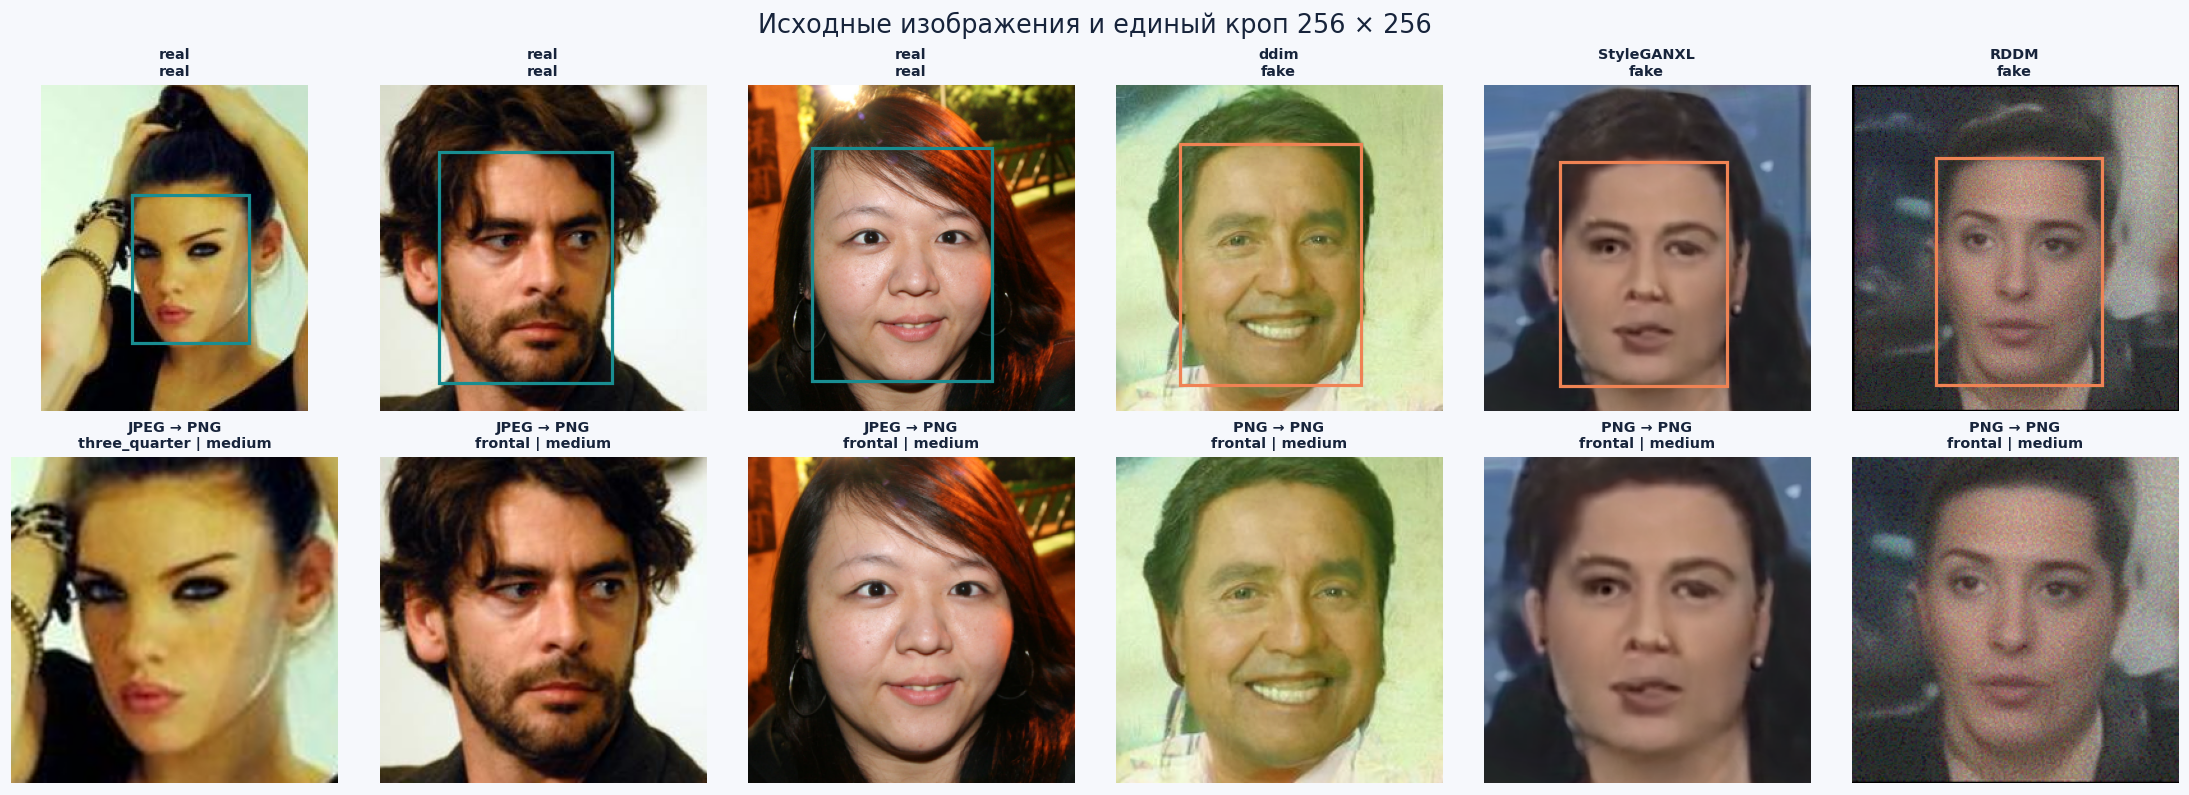

,provenance
режим,historical_pixel_artifacts
source_commit,cc4c3a0f4f928cb5113a399d5687048e0c59eb92
source_notebook_sha256,c3411479a7989eb0f9a3e9ea6ca5923e0c896bb02b1390...
metadata_sha256,ee34a665e869b25ffc18ba13381bb0576cabf189ca1598...


In [6]:
pixel_assets = E.pixel_illustrations(
    ROOT, faces, ROOT / "data/processed/df40/metadata.parquet",
)
historical_pixels = pixel_assets["mode"] == "historical_pixel_artifacts"
display(Markdown(
    "**Сохранённая иллюстрация предыдущего реального pixel-прогона.** "
    "Raw-файлы и кропы удалены после анализа; эта ячейка проверяет provenance и показывает сохранённый PNG."
    if historical_pixels else "**Свежая иллюстрация:** исходники и кропы прочитаны в этом запуске."
))
display(Image(filename=str(pixel_assets["figure_paths"]["examples"])))
display(pd.Series({
    "режим": pixel_assets["mode"],
    "source_commit": pixel_assets["manifest"].get("source_commit"),
    "source_notebook_sha256": pixel_assets["manifest"]["source_notebook_sha256"],
    "metadata_sha256": pixel_assets["manifest"]["metadata_sha256"],
}, name="provenance").to_frame())

## 4. Как часто исходный квадрат 1.3 × bbox вышел бы за изображение

Главная метрика - **доля исходных изображений**, у которых предложенный квадрат 1.3 хотя бы частично выходит за край. Площадь недостающей части внутри одного кропа считаем отдельно.

Препроцессор сохраняет `proposed_crop_bounds / proposed_padding_fraction` для исходного правила 1.3 и `crop_bounds / padding_fraction` для фактического adaptive-кропа. Поэтому диагностика исходного правила остаётся доступной после перехода на кроп без padding.

Считаем по всему DF40-сабсету до фильтрации обучения. Изображение учитываем один раз; primary-лицо выбираем по наибольшей площади bbox, при равенстве - по face_index. Отдельно показываем случай, где за край вышел бы кроп любого лица.

Для изображений без лица, с ошибкой декодирования или без измеримого квадрата сохраняем отдельный счётчик. Показываем доли от всех исходников и от измеримых primary-кропов. Median/P95 площади считаем среди измеримых предложенных квадратов, включая нули; значения только среди случаев с выходом приводим отдельно. Фактический adaptive-padding проверяем независимо.

,изображений
всего исходных изображений DF40,100000
измерим primary-кроп,99231
primary-кроп не измерен,769
primary-лицо непригодно для обучения,1980
изображений с флагом no_face,769
изображений с ошибкой декодирования,0
несколько записей лиц,77
фактических primary-кропов с padding,0
предложенный 1.3-кроп хотя бы частично за краем,86076
хотя бы один предложенный квадрат за краем,86077


,доля
primary за краем - доля ВСЕХ исходников,86.1%
primary за краем - доля ИЗМЕРЕННЫХ,86.7%
padding > 5% площади - доля ВСЕХ,40.0%
padding > 10% площади - доля ВСЕХ,19.9%
"median площади padding, включая нули",3.8%
"P95 площади padding, включая нули",23.9%
median площади среди кропов с padding,4.6%
P95 площади среди кропов с padding,25.6%
квадратных исходников - доля ВСЕХ,99.7%
квадратных исходников - доля с известным размером,99.7%


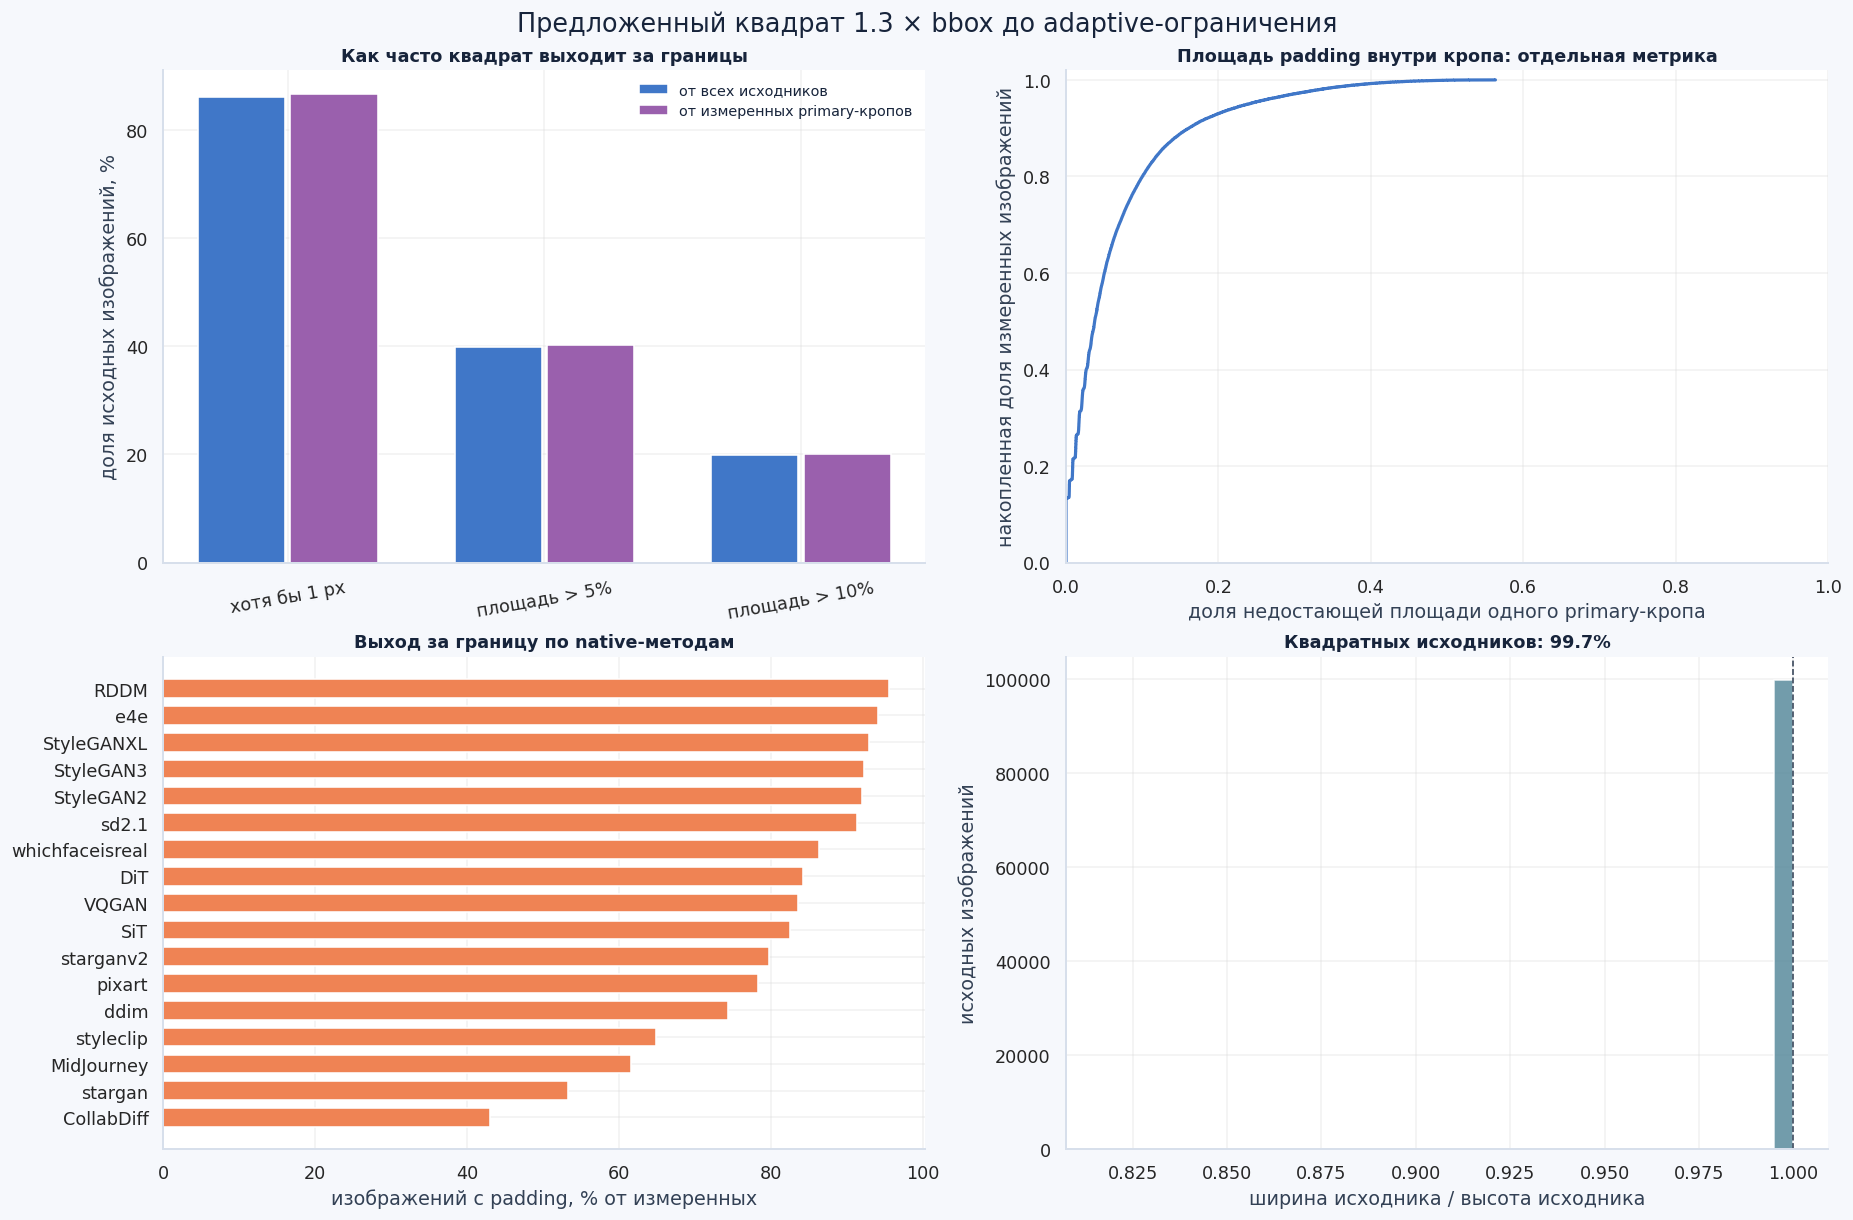

,input_images,measured_primary_images,images_padded,share_images_padded_all,share_images_padded_measured,share_images_padding_gt05_all,share_images_padding_gt10_all,padding_area_median,padding_area_p95,share_square_inputs_all,no_face_images,primary_bad_images
native_method,,,,,,,,,,,,
CollabDiff,322,316,136,42.2%,43.0%,19.9%,8.4%,0.0%,13.2%,50.0%,6,8
DiT,8629,8617,7255,84.1%,84.2%,31.3%,10.4%,2.8%,12.9%,100.0%,12,19
MidJourney,263,263,162,61.6%,61.6%,40.3%,25.1%,2.5%,27.9%,100.0%,0,0
RDDM,6346,5891,5629,88.7%,95.6%,45.1%,13.4%,4.9%,14.1%,100.0%,455,471
SiT,8629,8625,7121,82.5%,82.6%,31.2%,10.4%,2.6%,12.7%,100.0%,4,10
StyleGAN2,8629,8575,7882,91.3%,91.9%,30.3%,6.6%,3.0%,10.8%,100.0%,54,59
StyleGAN3,8629,8593,7921,91.8%,92.2%,29.5%,6.9%,3.0%,11.0%,100.0%,36,39
StyleGANXL,8629,8629,8014,92.9%,92.9%,25.4%,9.4%,2.4%,13.2%,100.0%,0,2
VQGAN,8629,8625,7210,83.6%,83.6%,26.6%,8.5%,2.2%,12.1%,100.0%,4,12


,input_images,measured_primary_images,images_padded,share_images_padded_all,share_images_padded_measured,share_images_padding_gt05_all,share_images_padding_gt10_all,padding_area_median,padding_area_p95,share_square_inputs_all,no_face_images,primary_bad_images
target,,,,,,,,,,,,
0,1287,1275,720,55.9%,56.5%,27.4%,13.2%,1.2%,15.4%,75.0%,12,18
1,98713,97956,85356,86.5%,87.1%,40.1%,20.0%,3.8%,24.1%,100.0%,757,1962


,input_images,measured_primary_images,images_padded,share_images_padded_all,share_images_padded_measured,share_images_padding_gt05_all,share_images_padding_gt10_all,padding_area_median,padding_area_p95,share_square_inputs_all,no_face_images,primary_bad_images
source_format,,,,,,,,,,,,
JPEG,12247,12224,10797,88.2%,88.3%,38.7%,14.4%,4.2%,14.1%,97.4%,23,32
PNG,87753,87007,75279,85.8%,86.5%,40.1%,20.7%,3.7%,25.5%,100.0%,746,1948


In [7]:
boundary = E.crop_boundary_summary(faces)
boundary_overall = boundary["overall"].iloc[0]
assert int(boundary_overall["input_images"]) == len(sample)
display(pd.Series({
    "всего исходных изображений DF40": int(boundary_overall["input_images"]),
    "измерим primary-кроп": int(boundary_overall["measured_primary_images"]),
    "primary-кроп не измерен": int(boundary_overall["unmeasured_primary_images"]),
    "primary-лицо непригодно для обучения": int(boundary_overall["primary_bad_images"]),
    "изображений с флагом no_face": int(boundary_overall["no_face_images"]),
    "изображений с ошибкой декодирования": int(boundary_overall["decoding_failed_images"]),
    "несколько записей лиц": int(boundary_overall["images_with_multiple_face_records"]),
    "фактических primary-кропов с padding": int(boundary_overall["actual_images_padded"]),
    "предложенный 1.3-кроп хотя бы частично за краем": int(boundary_overall["images_padded"]),
    "хотя бы один предложенный квадрат за краем": int(boundary_overall["images_any_face_padded"]),
}, name="изображений").to_frame())
display(pd.Series({
    "primary за краем - доля ВСЕХ исходников": boundary_overall["share_images_padded_all"],
    "primary за краем - доля ИЗМЕРЕННЫХ": boundary_overall["share_images_padded_measured"],
    "padding > 5% площади - доля ВСЕХ": boundary_overall["share_images_padding_gt05_all"],
    "padding > 10% площади - доля ВСЕХ": boundary_overall["share_images_padding_gt10_all"],
    "median площади padding, включая нули": boundary_overall["padding_area_median"],
    "P95 площади padding, включая нули": boundary_overall["padding_area_p95"],
    "median площади среди кропов с padding": boundary_overall["padding_area_median_among_padded"],
    "P95 площади среди кропов с padding": boundary_overall["padding_area_p95_among_padded"],
    "квадратных исходников - доля ВСЕХ": boundary_overall["share_square_inputs_all"],
    "квадратных исходников - доля с известным размером": boundary_overall["share_square_inputs_known_dimensions"],
}, name="доля").to_frame().style.format("{:.1%}", na_rep="-"))
E.plot_crop_boundaries(boundary)
plt.show()
boundary_columns = [
    "input_images", "measured_primary_images", "images_padded",
    "share_images_padded_all", "share_images_padded_measured",
    "share_images_padding_gt05_all", "share_images_padding_gt10_all",
    "padding_area_median", "padding_area_p95",
    "share_square_inputs_all", "no_face_images", "primary_bad_images",
]
boundary_percent = {
    name: "{:.1%}" for name in boundary_columns
    if name.startswith("share_") or name.startswith("padding_area_")
}
for feature in ("native_method", "target", "source_format"):
    table = boundary["by_" + feature]
    display(table.set_index(feature)[boundary_columns].style.format(boundary_percent, na_rep="-"))
if "crop_policy" in faces and faces["crop_policy"].eq("adaptive").all():
    assert int(boundary_overall["actual_images_padded"]) == 0

,input_images,measured_primary_images,share_images_padded_all,share_images_padded_measured,padding_area_median,padding_area_p95,share_square_inputs_all,no_face_images
dataset,,,,,,,,
df40,100000,99231,86.1%,86.7%,3.8%,23.9%,99.7%,769
140k,20000,19983,84.6%,84.7%,5.4%,19.5%,100.0%,17
openforensics,20000,20000,7.2%,7.2%,0.0%,5.2%,2.1%,0
mffi,20000,19746,76.9%,77.9%,3.7%,15.4%,99.2%,254


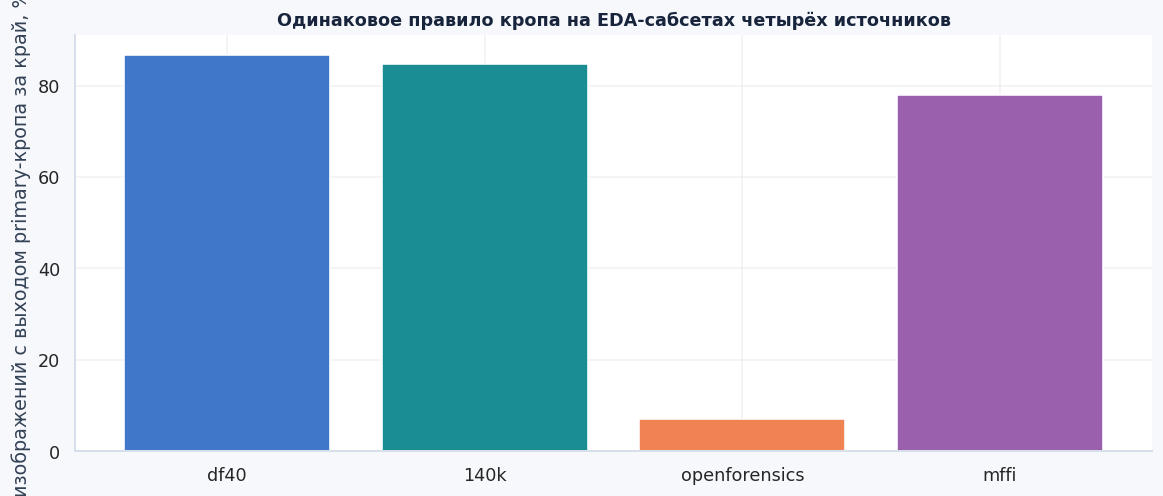

In [8]:
boundary_comparisons = []
for dataset in E.DATASETS:
    metadata_path = ROOT / f"data/processed/{dataset}/metadata.parquet"
    if metadata_path.is_file():
        current_faces = faces if dataset == "df40" else pd.read_parquet(metadata_path)
        current_summary = boundary if dataset == "df40" else E.crop_boundary_summary(current_faces)
        boundary_comparisons.append(current_summary["overall"].assign(dataset=dataset))
boundary_comparison = pd.concat(boundary_comparisons, ignore_index=True).set_index("dataset")
display(boundary_comparison[[
    "input_images", "measured_primary_images", "share_images_padded_all",
    "share_images_padded_measured", "padding_area_median", "padding_area_p95",
    "share_square_inputs_all", "no_face_images",
]].style.format(boundary_percent, na_rep="-"))
fig, ax = plt.subplots(figsize=(10, 4.2), layout="constrained")
comparison_percent = 100 * boundary_comparison["share_images_padded_measured"]
ax.bar(comparison_percent.index, comparison_percent, color=["#4077C8", "#198D91", "#EF8354", "#9A60AD"][:len(comparison_percent)])
ax.set_ylabel("изображений с выходом primary-кропа за край, %")
ax.set_title("Одинаковое правило кропа на EDA-сабсетах четырёх источников")
plt.show()

## 5. Геометрия, формат и признаки качества

Размеры и исходный формат пересчитываем по metadata уникальных исходных изображений. Чёткость, высокие частоты и размер исходного файла измерены по фиксированной подвыборке до 3000 подходящих кропов. При metadata-only повторном запуске показываем прежние реальные pixel-панели и сохранённую агрегированную таблицу. Новых измерений пикселей в этом режиме нет.

Уникальных исходников по metadata: **100,000**. Pixel-диагностика охватывает **3,000** реальных кропов. Ниже сохранённые панели и агрегаты прошлого прогона.

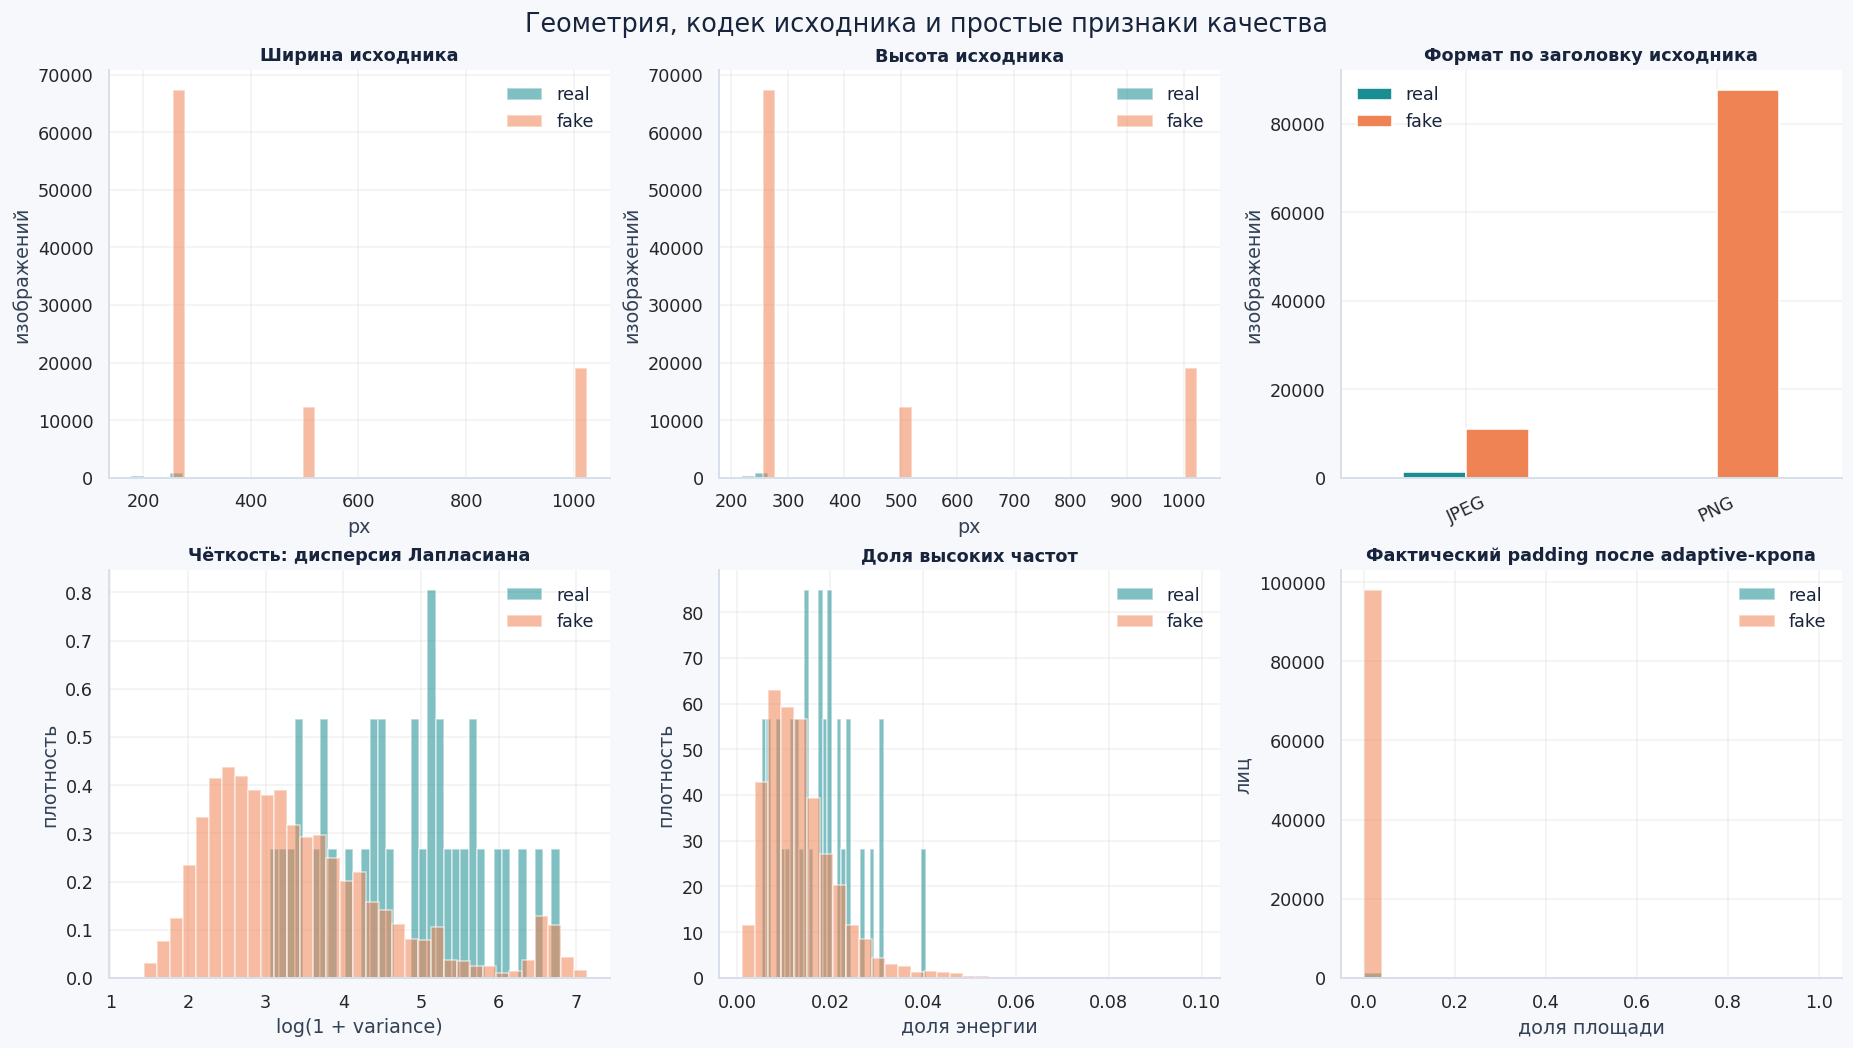

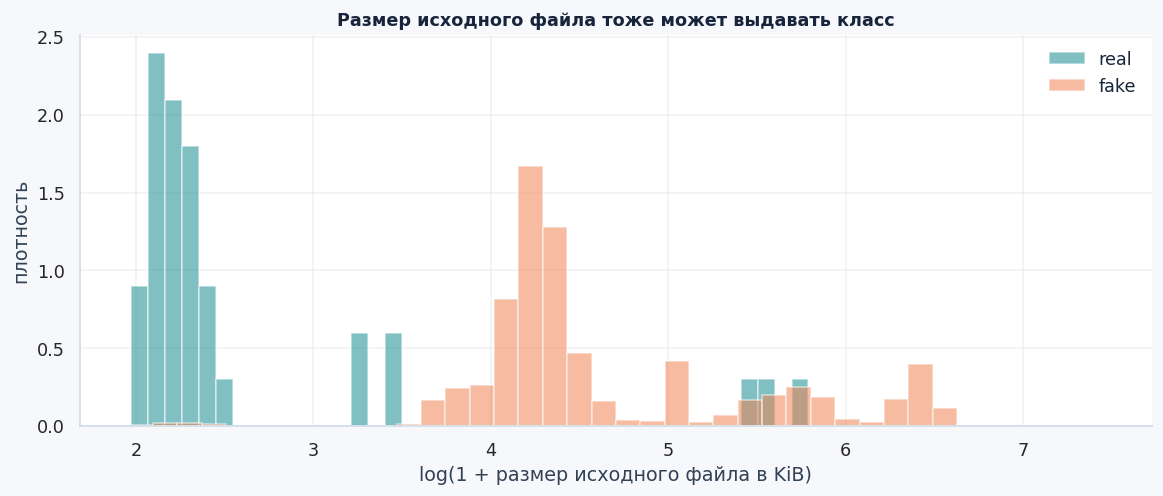

,лиц,чёткость_медиана,HF_медиана,размер_KiB_медиана
target,,,,
real,35,138.553,0.017,8.464
fake,2965,22.691,0.012,74.801


In [9]:
images = E.image_table(faces)
display(Markdown(
    f"Уникальных исходников по metadata: **{len(images):,}**. "
    f"Pixel-диагностика охватывает **{pixel_assets['manifest']['quality_sample_size']:,}** реальных кропов. "
    + ("Ниже сохранённые панели и агрегаты прошлого прогона." if historical_pixels
       else "Ниже результаты чтения пикселей в текущем запуске.")
))
display(Image(filename=str(pixel_assets["figure_paths"]["image_properties"])))
display(Image(filename=str(pixel_assets["figure_paths"]["source_files"])))
display(HTML(pixel_assets["quality_summary_html"]))

In [10]:
format_table = pd.crosstab(
    [images["generator"], images["target"]],
    images["source_format"].fillna("unknown"),
    normalize="index",
)
display(format_table.style.format("{:.1%}").background_gradient(cmap="Blues"))
verified = images["source_format_verified"].fillna(False).astype(bool)
display(pd.Series({
    "формат подтверждён заголовком": int(verified.sum()),
    "формат не подтверждён": int((~verified).sum()),
    "авторских сплитов": sample["author_split"].nunique(),
    "исходных форматов": images["source_format"].nunique(),
}, name="изображений").to_frame())

,source_format,JPEG,PNG
generator,target,,
CollabDiff,1,0.0%,100.0%
DiT,1,0.0%,100.0%
MidJourney,1,0.0%,100.0%
RDDM,1,0.0%,100.0%
SiT,1,0.0%,100.0%
StyleGAN2,1,0.0%,100.0%
StyleGAN3,1,0.0%,100.0%
StyleGANXL,1,0.0%,100.0%
VQGAN,1,0.0%,100.0%


,изображений
формат подтверждён заголовком,100000
формат не подтверждён,0
авторских сплитов,2
исходных форматов,2


## 6. Поза, освещение и доля маски лица

YuNet проверяет лица; доверенные авторские bbox сохраняются. MediaPipe Face Landmarker оценивает yaw/pitch/roll на фактическом adaptive-кропе. Бины каждого угла по модулю: анфас < 15°, полупрофиль 15-45°, профиль > 45°.

Для маски лица приоритет имеет валидная авторская разметка. Если её нет, используем MediaPipe FaceOval. Пустую или невалидную авторскую маску отмечаем флагом и пробуем FaceOval. `mask_source` сохраняет annotation / mediapipe_face_oval / missing и служит только аудитом покрытия; при разбиении его не балансируем.

Свет L* считаем по выбранной маске внутри фактического кропа. Бины: dark < 35, medium 35-65, bright ≥ 65. Доля лица `face_mask_fraction_of_crop` - площадь этой же маски внутри кропа, делённая на площадь фактического квадрата. Если маски нет, обе величины остаются неизвестными.

Для EDA долю маски разбиваем на четыре равных интервала: [0, 0.25), [0.25, 0.5), [0.5, 0.75), [0.75, 1], плюс unknown. После quality-фильтра ≤ 0.25 и unknown исключены; в обучаемых сплитах балансируем три оставшихся диапазона. Bbox не используется как подстановка площади маски.

Таблица пропусков учитывает все строки обработки, в том числе записи без найденного лица. Число строк метаданных, число bbox, число сохранённых кропов и eligible считаем отдельно.

После измерения исключаем известную долю маски ≤ 0.25 с флагом face_mask_too_small и неизвестную/невалидную долю с face_mask_missing. Неизвестный генератор или модель сами по себе не исключаются.

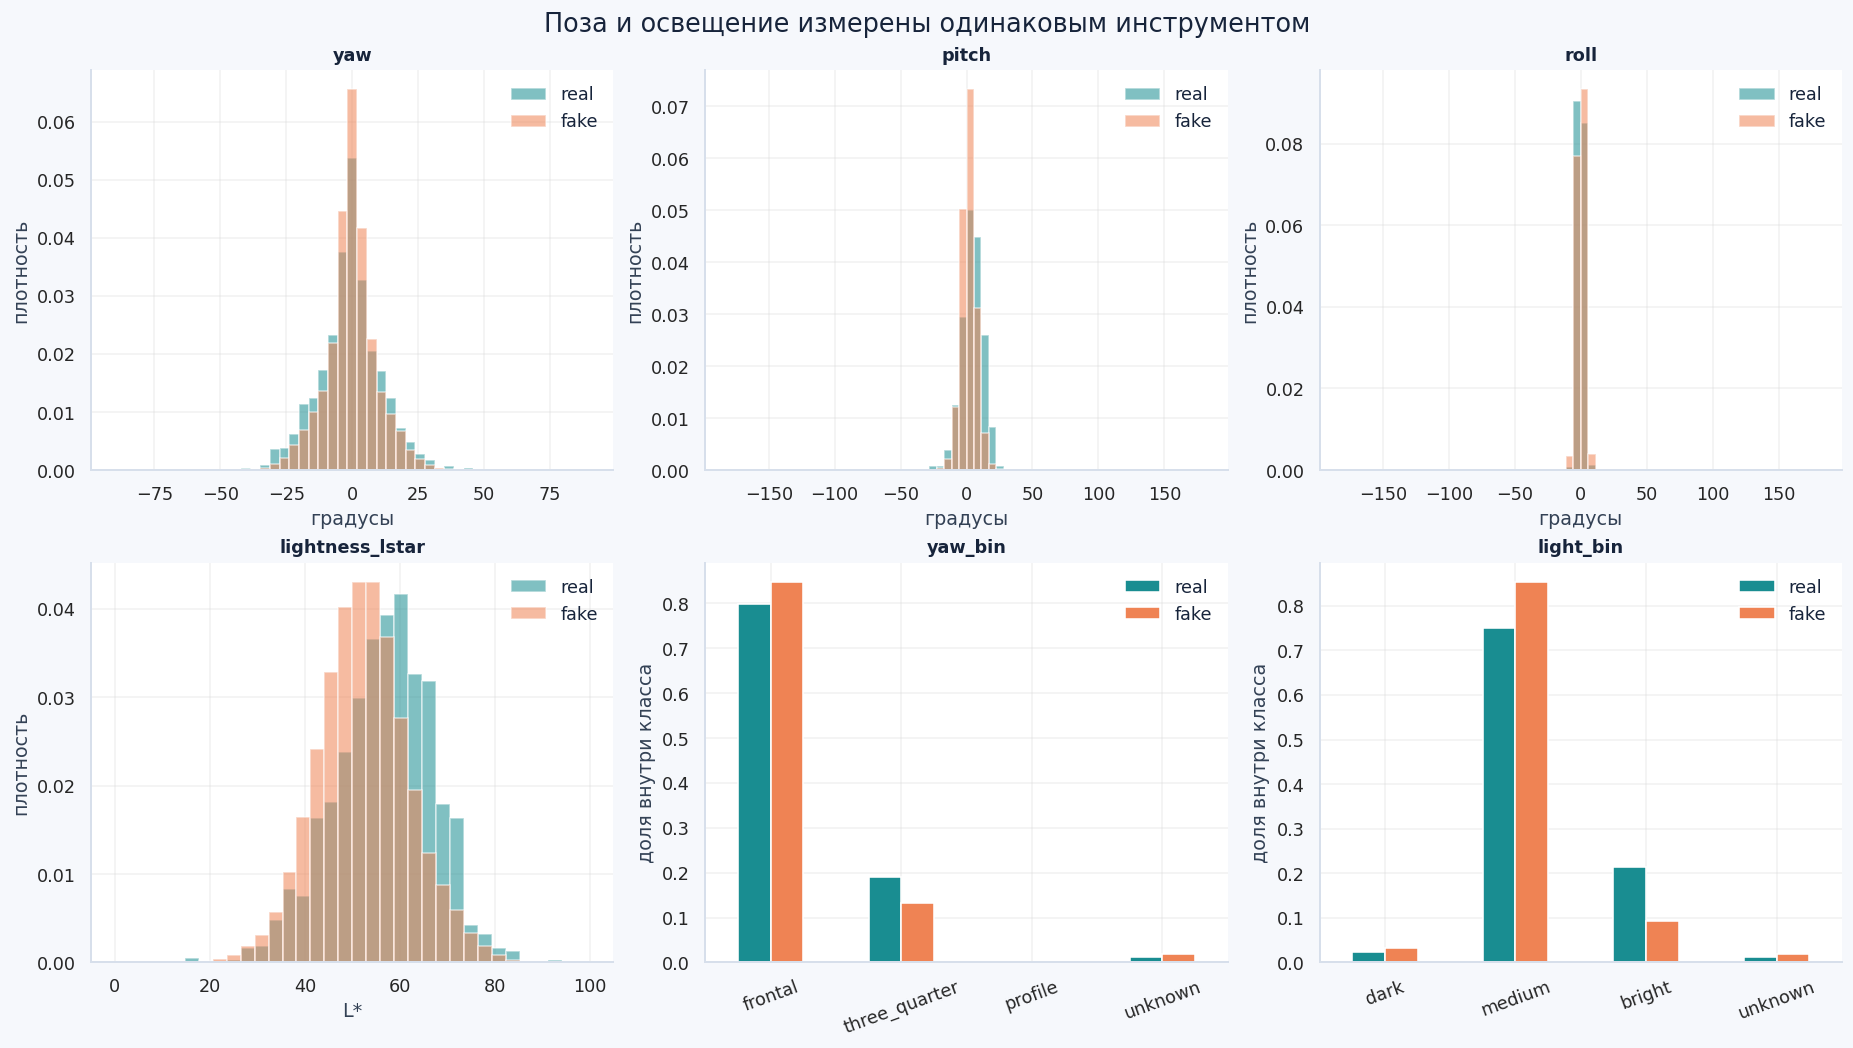

,target,признак,не измерено,доля
0,0,yaw,16,1.2%
1,1,yaw,1940,2.0%
2,0,pitch,16,1.2%
3,1,pitch,1940,2.0%
4,0,roll,16,1.2%
5,1,roll,1940,2.0%
6,0,lightness_lstar,16,1.2%
7,1,lightness_lstar,1940,2.0%
8,0,face_mask_fraction_of_crop,16,1.2%
9,1,face_mask_fraction_of_crop,1940,2.0%


yaw         pitch          roll        lightness_lstar         \
        count median  count median  count median           count median   
target                                                                    
real     1272 -0.801   1272  4.933   1272 -0.036            1272 57.350   
fake    96858 -0.190  96858  1.653  96858  0.239           96858 52.304   

       padding_fraction         
                  count median  
target                          
real               1276  0.000  
fake              98041  0.000

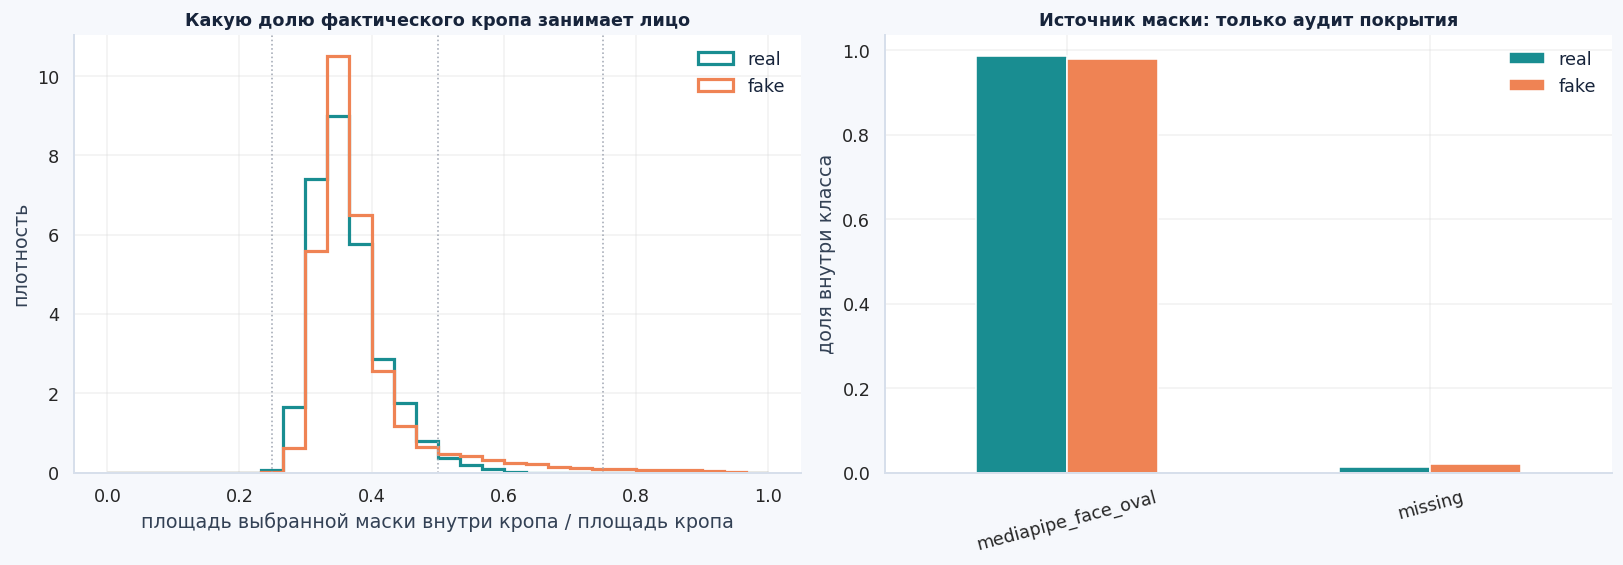

,count,median
target,,
0,1272,0.354
1,96858,0.361


mask_source,mediapipe_face_oval,missing
target,,
0,98.8%,1.2%
1,98.0%,2.0%


,dataset,target,processing_records,known_mask_fraction,missing_mask_fraction,mask_fraction_le_threshold,excluded_face_mask_too_small,excluded_face_mask_missing,eligible_current,eligible_violating_mask_rule,eligible_unknown_generator
0,DF40,0,1288,1272,16,1,1,16,1269,0,0
1,DF40,1,98798,96858,1940,29,29,1940,96751,0,0


In [11]:
E.plot_attributes(faces)
plt.show()
missing = E.missing_table(faces)
display(missing.style.format({"доля": "{:.1%}"}))
numeric = [column for column in ["yaw", "pitch", "roll", "lightness_lstar", "padding_fraction"] if column in faces]
display(faces.groupby("target")[numeric].agg(["count", "median"]).rename(index={0: "real", 1: "fake"}))
E.plot_face_mask_fraction(faces)
plt.show()
display(faces.groupby("target")["face_mask_fraction_of_crop"].agg(["count", "median"]))
if "mask_source" in faces:
    display(pd.crosstab(faces["target"], faces["mask_source"].fillna("missing"), normalize="index").style.format("{:.1%}"))
display(E.mask_quality_summary(faces, threshold=0.25))

## 7. Какие лица исключаем

Не берём лица меньше 32 px и кропы с полезной видимой частью лица меньше 32 px, конфликтующую разметку одного лица, кропы с соседом другой метки, невалидные рамки и неоднозначную image-level разметку нескольких лиц. Отсутствие измерения MediaPipe - отдельный информационный флаг; оно само по себе не превращает лицо в fake или real.

Дубликаты и противоречия между датасетами проверяются после объединения всех источников. Полный кадр OpenForensics может содержать сразу real и fake, поэтому одинаковый хеш кадра объединяет группы, но не означает конфликт меток разных лиц.

Отдельный quality-only этап исключает маску с долей ≤ 25% и отсутствие измеримой маски. Неизвестная поза сама по себе не является таким фильтром, если маска измерена. Неизвестную модель генерации сохраняем.

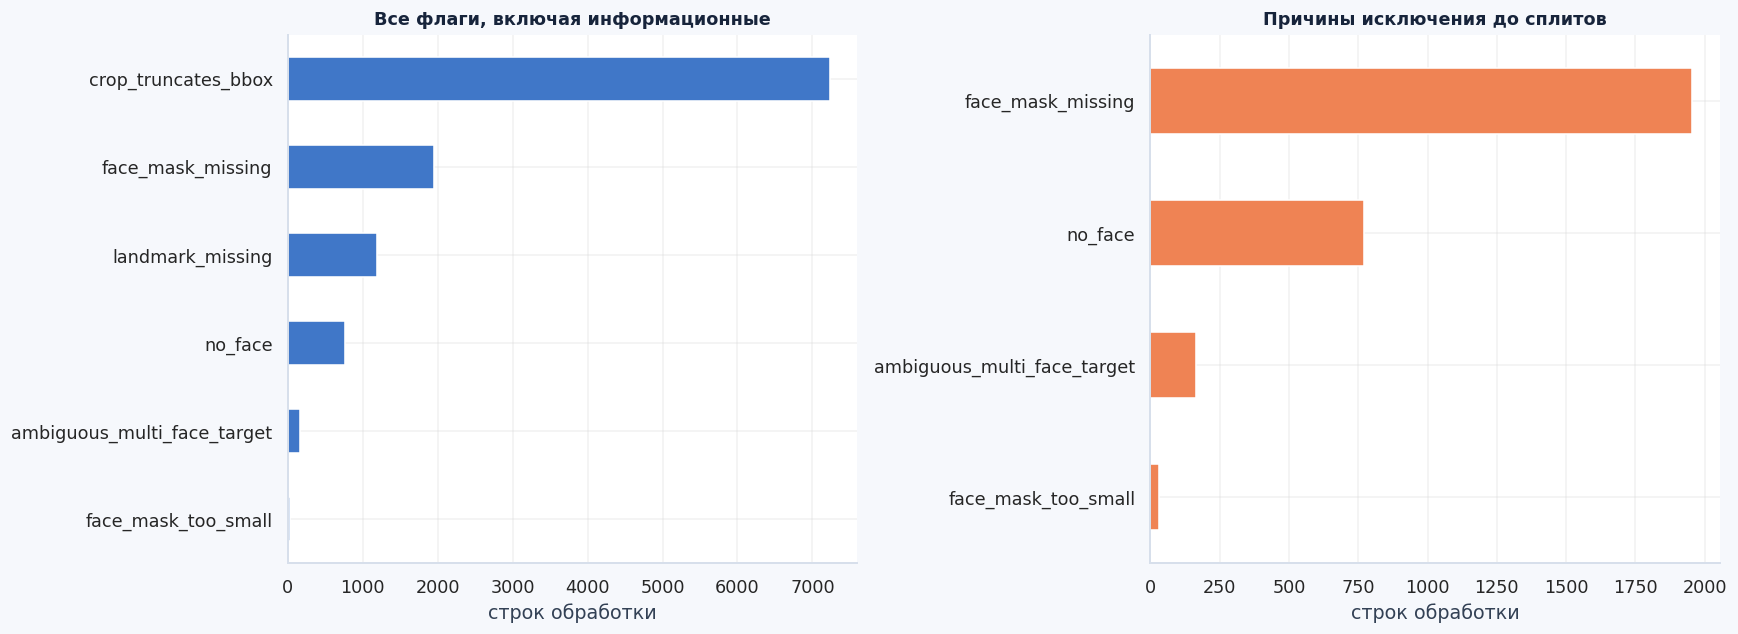

,строк
crop_truncates_bbox,7232
face_mask_missing,1956
landmark_missing,1187
no_face,769
ambiguous_multi_face_target,163
face_mask_too_small,30


,количество
исключено до объединения,2066
пригодно до глобального дедупа,98020
исходных image SHA с повторами,2943
crop SHA с повторами,2927
checkpoint reused images,0


In [12]:
E.plot_flags(faces)
plt.show()
display(E.flag_counts(faces).to_frame())
display(pd.Series({
    "исключено до объединения": int((~faces["eligible"]).sum()),
    "пригодно до глобального дедупа": int(faces["eligible"].sum()),
    "исходных image SHA с повторами": int(images["image_sha256"].value_counts().gt(1).sum()),
    "crop SHA с повторами": int(faces["crop_sha256"].dropna().value_counts().gt(1).sum()),
    "checkpoint reused images": preprocessing_audit.get("reused_images", 0),
}, name="количество").to_frame())

## 8. Методология композитных train / validate / test

**Общая таблица.** В обучаемой таблице строка соответствует одному лицу; ошибки обработки остаются отдельными записями. Сохраняем бинарный таргет, датасет, генератор, тип манипуляции, исходный формат, авторскую часть, группу источника, известную identity-группу, углы, L*, флаги и хеши. У OpenForensics метки берём по лицам из оригинальной разметки, а не по всему кадру. У 140k сохраняем StyleGAN / FFHQ. У MFFI неизвестные генераторы и трансформации остаются `unknown`; баланс неизвестной разметки генераторов нельзя подтвердить.

**Глобальное разбиение 70/15/15.** Авторские train/validation/test сохраняем как метаданные и не используем как ограничения. После исключения плохих лиц и поиска дубликатов объединяем все четыре источника в общий пул. Целевые доли - 70% train, 15% validate, 15% test. Группы источников и подтверждённых копий нельзя разрывать. Размер группы может немного смещать точные доли.

**Группы и оверлапы.** Исходный кадр/изображение, его трансформации, связанные source ID и известные identity ID держим вместе. Проверяем исходные байты, декодированные пиксели и кропы. Противоположные метки одного точного кропа или одного совпавшего лица в одинаковом исходнике исключаем. Для сопоставления лиц в одинаковом кадре используем IoU рамок; разные лица смешанного кадра не объявляем конфликтом.

Перцептивный хеш с расстоянием до 4 бит используется только для поиска кандидатов. Объединяем пару после точного совпадения хеша либо проверки пикселей: нормализованные кропы, а при совместимом соотношении сторон также исходники, должны пройти пороги RGB MAE и SSIM. Отдельно отсекаем сравнения с недостаточной текстурой. Точные настройки и число подтверждённых, отклонённых и недоступных пар выводим из финального аудита ниже. Недоступность совместимой пары для проверки помечаем near_duplicate_verification_missing и исключаем соответствующие строки. Сходство одного pHash не создаёт связь.

Подтверждённые связи превращаем в компоненты и целиком распределяем между тремя частями. Пересечение прежней авторской границы само по себе не является причиной удаления. Затем независимо пересчитываем пересечения групп и точных хешей итоговых частей. Пиксельная проверка выявляет близкие копии, но не устанавливает identity человека. Если пиксели уже удалены, используем ранее проверенные связи из group cache только после проверки fingerprint входных metadata и кода; audit показывает, какие проверки переиспользованы.

**Баланс.** Группы распределяем с оптимизацией маргинальных частот: датасет, таргет, генератор, тип манипуляции, бины углов, бины света и исходный формат. Для формата дополнительно учитываем генератор внутри dataset + target. Целевые маргинальные доли берём из пригодного объединённого пула, отдельно учитываем глобальные частоты dataset, target и source_format. Сначала выделяем test, затем validation. Обмен групп улучшает баланс без разрыва source-групп.

Целостность групп важнее точного совпадения гистограмм. Финальный отчёт показывает остаточные расхождения и отсутствующие страты. Неполная identity-разметка ограничивает проверку одного человека между разными фото.

Дополнительно балансируем геометрию: минимальную сторону лица по границам 32/64/128/256 px, долю padding (0, до 25%, больше 25%) и минимальную сторону исходника (<256, 256-512, ≥512 px). Эти признаки получаем из уже сохранённых рамок и размеров, повторный прогон моделей для них не нужен.

mask_source сохраняем только для аудита. После quality-фильтра при разбиении балансируем три оставшихся диапазона доли маски лица; ≤ 0.25 и unknown в обучаемые сплиты не входят.

До разбиения канонизируем только известные синонимы методов. Бинарный target при этом не меняется; raw-метки и авторские native_method/native_family сохраняются. При наличии transformation-тегов учитываем каждый тег отдельно, без превращения всех комбинаций в новые классы.

Числовые каталоги EFS описывают батчи выходных изображений внутри generator/domain/archive. generation_batch сохраняем только для аудита: сам батч не связывает изображения в одну split-группу. При неизвестной lineage исходная единица EFS - отдельное изображение; связи добавляют лишь подтверждённые дубликаты или явные source ID. Для всех FE без документированного source ID используем отдельное изображение с неизвестной lineage. Общие каталоги fake/inversions и числовые выходные каталоги не создают source или identity-связь. Явные published source ID у FF/CDF и подтверждённые пары real/fake сохраняем. Разные неизвестные source-группы не означают разных людей. До финальной сборки исправлены ложные связи по EFS-батчам, числовым именам и общему inversions-каталогу; отладочные потери этих строк не выдаём за реальные исключения.

В авторском [SD-семплере](https://github.com/YZY-stack/DF40/blob/ce808160e0df31544b41c7b60b942849ba88bca8/EFS_finetune_code/diffusion_based/test_scripts/test_sd_lora.py#L112-L121) имена реальных кадров задают seed/имена выходов, а не входное лицо; [Algorithm 3 и Appendix A.2.4](https://arxiv.org/html/2406.13495v2) описывают EFS-генерацию из шума после domain fine-tuning. Поэтому такие имена не создают глобальную FF identity-группу.

## 9. Исполняемая демонстрация сборки

Предыдущие шаги скачивания и препроцессинга создают четыре `metadata.parquet`. Следующая ячейка каждый раз действительно запускает общий CLI на этих результатах. Новое скачивание и повторная обработка лиц для этой демонстрации не нужны.

Эквивалентная команда:

```bash
python scripts/build_composite_splits.py \
  --manifest data/processed/df40/metadata.parquet data/processed/140k/metadata.parquet data/processed/openforensics/metadata.parquet data/processed/mffi/metadata.parquet \
  --output data/splits/composite --config configs/composite.yml
```

Результат: `train.parquet / validate.parquet / test.parquet`, те же манифесты в CSV, отдельный список исключений и `audit.json`. Сами изображения остаются по путям кропов в этих манифестах.

Сборщик всегда запускается с global_balanced. Для повторного запуска без изображений передаём проверенный group cache. Он переиспользует ранее подтверждённые связи, а не объявляет недоступные картинки проверенными заново. При изменении входных metadata нужен новый валидный cache или повторный прогон по пикселям.

In [13]:
face_manifests = [ROOT / f"data/processed/{dataset}/metadata.parquet" for dataset in E.DATASETS]
missing_manifests = [str(path) for path in face_manifests if not path.is_file()]
if missing_manifests:
    raise FileNotFoundError("Сначала запустите загрузку, индексацию и препроцессинг: " + ", ".join(missing_manifests))
preprocessing_versions = []
for dataset in E.DATASETS:
    audit_path = ROOT / f"data/processed/{dataset}/preprocessing_audit.json"
    source_audit = json.loads(audit_path.read_text())
    settings = source_audit["provenance"]["settings"]
    if settings.get("crop_policy") != "adaptive" or settings.get("size") != 256 or settings.get("expansion") != 1.3:
        raise ValueError(f"Перезапустите {dataset} через preprocess.py --crop-policy adaptive с размером 256 и expansion 1.3")
    preprocessing_versions.append(source_audit["provenance"]["preprocessor_source_sha256"])
assert len(set(preprocessing_versions)) == 1, "Четыре источника должны пройти одну версию препроцессора"
fresh_group_cache = ROOT / "data/processed/verified_groups"
group_cache = (fresh_group_cache if (fresh_group_cache / "manifest.json").is_file()
               else ROOT / "data/group_cache/verified_groups")
print("Verified group cache:", group_cache)
command = [
    sys.executable, str(ROOT / "scripts/build_composite_splits.py"),
    "--manifest", *map(str, face_manifests),
    "--output", str(ROOT / "data/splits/composite"),
    "--config", str(ROOT / "configs/composite.yml"),
    "--split-policy", "global_balanced",
    "--group-cache", str(group_cache),
]
process = subprocess.run(command, cwd=ROOT, check=True, text=True, capture_output=True)
print(process.stdout.strip())
if process.stderr.strip():
    print(process.stderr.strip())
parts, composite_audit = E.load_composite(ROOT)
assert composite_audit["split_policy"] == "global_balanced"
assert all(len(parts[name]) > 0 for name in ("train", "validate", "test"))
display(pd.DataFrame({
    "количество": [len(parts[name]) for name in ("train", "validate", "test", "excluded")],
    "единица": ["лиц", "лиц", "лиц", "строк обработки"],
}, index=["train", "validate", "test", "excluded"]))
display(pd.DataFrame.from_dict(composite_audit["author_split_policies"], orient="index"))
display(pd.Series(composite_audit.get("group_cache", {}), name="group cache audit").to_frame())
for partition in ("train", "validate", "test"):
    usable_mask_fraction = pd.to_numeric(parts[partition]["face_mask_fraction_of_crop"], errors="coerce")
    assert usable_mask_fraction.gt(0.25).all() and usable_mask_fraction.le(1).all()

Verified group cache: /home/valievayaz/df40_eda_20261109/repo/data/group_cache/verified_groups


{"train_rows": 128054, "validate_rows": 27440, "test_rows": 27440, "excluded_rows": 18785, "ready_for_training": true}


,количество,единица
train,128054,лиц
validate,27440,лиц
test,27440,лиц
excluded,18785,строк обработки


,policy,source_partitions,basis,author_parts_ignored
140k,global_balanced,"[test, train, validate]",all_eligible_verified_groups,True
DF40,global_balanced,"[test, train]",all_eligible_verified_groups,True
mffi,global_balanced,"[test, train, validate]",all_eligible_verified_groups,True
openforensics,global_balanced,"[test, train, validate]",all_eligible_verified_groups,True


,group cache audit
cache_path,/home/valievayaz/df40_eda_20261109/repo/data/g...
reused,True
verified_now,False
origin,bootstrap_previous_verified_run
bootstrap_from_previous_verified_run,True
rows,201719
groups,151389
input_digest,3cb4030c8fef15726010ba036cced1c9209f6a8cf2b34f...
cache_file_sha256,16c28a2d5ffe11a278f61cc630d41fb66011f592c1b0fb...
logic_fingerprints_sha256,b51502724ec9f54063d2e4abe3970dfddeda51a6f42a6b...


### Бинарный таргет и вспомогательная таксономия

Бинарный `target` сохраняет только real/fake. Известные генераторы, типы манипуляций и transformation-теги остаются отдельными метаданными для стратификации и анализа.

Перед сборкой применяется версионированный `configs/label_aliases.json`: синонимы одного метода приводятся к общему ID между датасетами. Версии StyleGAN2/StyleGAN3 и разные Stable Diffusion не склеиваются. Исходные значения сохраняются в `generator_raw / manipulation_raw / transformation_raw`; `native_method / native_family` остаются авторскими.

Transformation-теги балансируются по отдельным признакам присутствия внутри dataset + target. Если у лица несколько тегов, знаменатель каждой доли - число лиц, а не сумма тегов. Неизвестная разметка остаётся неизвестной. Для сравнения тега между сплитами считаем TV/JS его бинарного присутствия.

In [14]:
taxonomy = E.taxonomy_table(parts)
normalization_audit = composite_audit["label_normalization"]
display(pd.Series({
    "registry_version": normalization_audit.get("registry_version", "unknown"),
    "входных строк обработки": composite_audit["input_rows"],
    "target": "0 = real, 1 = fake; неизменён при нормализации",
}, name="нормализация").to_frame())
coverage = pd.DataFrame.from_dict(normalization_audit.get("columns", {}), orient="index")
coverage_columns = [name for name in ("rows", "changed_rows", "missing_rows") if name in coverage]
if coverage_columns:
    coverage = coverage[coverage_columns].apply(pd.to_numeric, errors="coerce")
    if {"rows", "missing_rows"} <= set(coverage):
        coverage["missing_share"] = coverage["missing_rows"] / coverage["rows"].replace(0, np.nan)
    display(coverage.style.format({"missing_share": "{:.1%}"}, na_rep="-"))
for field, table in taxonomy.groupby("field", sort=False):
    display(Markdown("**" + field + ": исходная и общая метка**"))
    display(table.sort_values(["dataset", "records"], ascending=[True, False]))

,нормализация
registry_version,2026-11-09.1
входных строк обработки,201719
target,"0 = real, 1 = fake; неизменён при нормализации"


,rows,changed_rows,missing_rows,missing_share
generator,201719,89692,74971,37.2%
manipulation,201719,108798,74971,37.2%
transformation,201719,201719,201719,100.0%


**generator: исходная и общая метка**

,dataset,field,raw,canonical,records
1,140k,generator,real,real,10024
0,140k,generator,StyleGAN,stylegan,10000
15,DF40,generator,sd2.1,stable_diffusion_2_1,12197
12,DF40,generator,e4e,e4e,9701
3,DF40,generator,DiT,dit_xl_2,8629
6,DF40,generator,SiT,sit_xl_2,8629
7,DF40,generator,StyleGAN2,stylegan2,8629
8,DF40,generator,StyleGAN3,stylegan3,8629
9,DF40,generator,StyleGANXL,stylegan_xl,8629
10,DF40,generator,VQGAN,vqgan,8629


**manipulation: исходная и общая метка**

,dataset,field,raw,canonical,records
24,140k,manipulation,real,real,10024
23,140k,manipulation,EFS,face_synthesis,10000
25,DF40,manipulation,EFS,face_synthesis,87838
26,DF40,manipulation,FE,face_edit,10960
27,DF40,manipulation,real,real,1288
29,mffi,manipulation,unknown,unknown,13482
28,mffi,manipulation,real,real,6638
30,openforensics,manipulation,unknown,unknown,61489


**transformation: исходная и общая метка**

,dataset,field,raw,canonical,records
31,140k,transformation,None,unknown,20024
32,DF40,transformation,None,unknown,100086
33,mffi,transformation,None,unknown,20120
34,openforensics,transformation,None,unknown,61489


### Формат исходника и таргет

Проверяем связь на реально подготовленных лицах четырёх источников, прошедших первоначальные фильтры. Единица таблицы - лицо; OpenForensics может содержать лица разных классов в одном исходнике. source_format берём из заголовка исходного файла. Равные форматные доли между сплитами не устраняют связь кодека с классом внутри датасета. Сохранение кропов в PNG не добавляет JPEG-сжатия и не отменяет уже присутствовавшие артефакты исходника.

In [15]:
prepared_faces = pd.concat([pd.read_parquet(path, columns=["dataset", "source_format", "target", "eligible"]) for path in face_manifests], ignore_index=True)
prepared_eligible = prepared_faces.loc[prepared_faces["eligible"].fillna(False)]
format_target = E.format_target_table(prepared_eligible)
display(format_target.style.format({"fake_share": "{:.1%}"}))
format_exclusive = format_target.loc[format_target["only_target"].ne("mixed")]
display(format_exclusive)
display(Markdown(E.format_target_finding(format_target)))

target,dataset,source_format,real,fake,total,fake_share,only_target
0,140k,JPEG,9939,9998,19937,50.1%,mixed
1,DF40,PNG,0,85805,85805,100.0%,fake
2,DF40,JPEG,1269,10946,12215,89.6%,mixed
3,mffi,JPEG,6591,13027,19618,66.4%,mixed
4,openforensics,JPEG,24286,25816,50102,51.5%,mixed


target,dataset,source_format,real,fake,total,fake_share,only_target
1,DF40,PNG,0,85805,85805,1.000,fake


**140k**: каждый представленный формат встречается у обоих таргетов.

**DF40**: PNG только у fake (лиц: 85,805).

**mffi**: каждый представленный формат встречается у обоих таргетов.

**openforensics**: каждый представленный формат встречается у обоих таргетов.

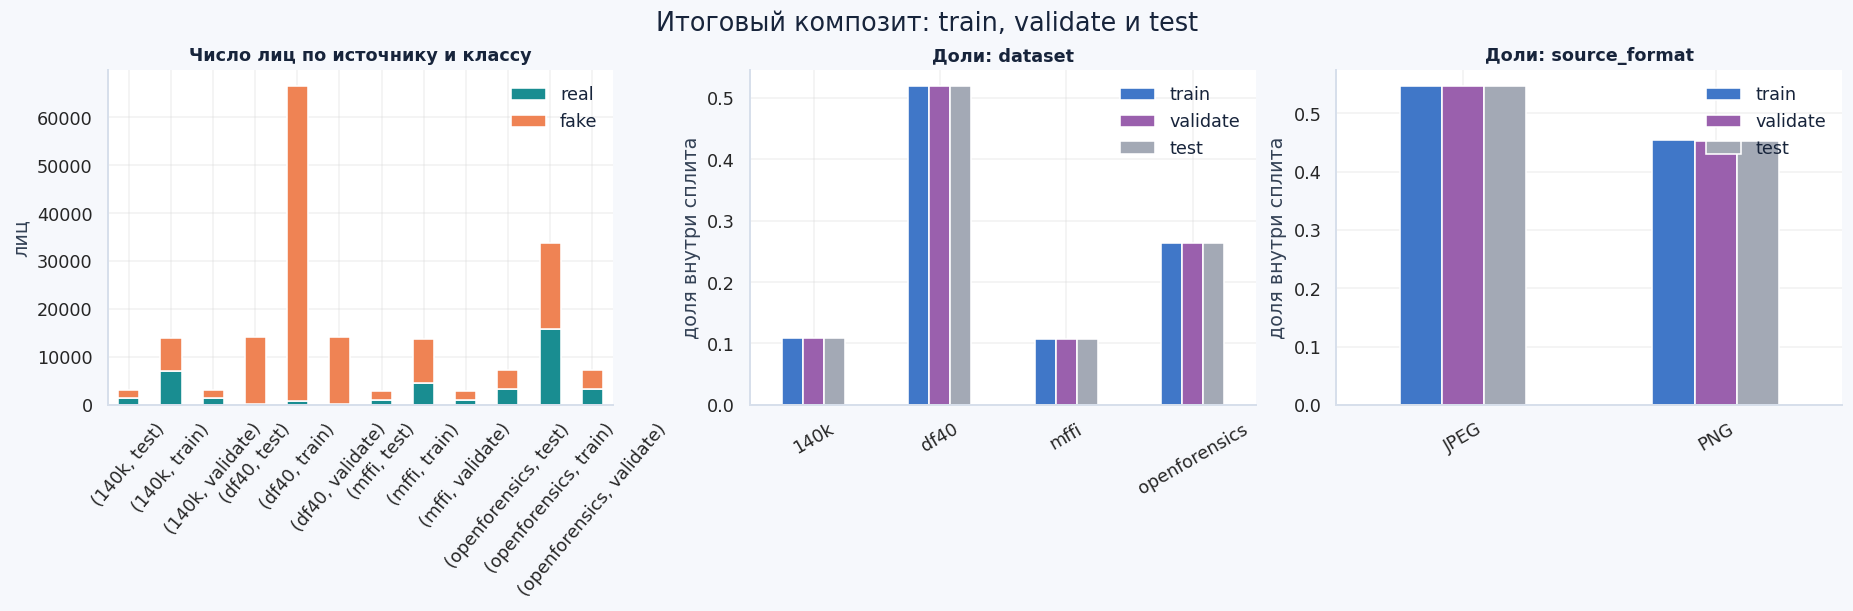

final_split                                train  validate  test
dataset       generator            target                       
140k          real                 0        6957      1491  1491
              stylegan             1        6998      1500  1500
DF40          collabdiff           1         113        24    24
              ddim                 1        5887      1261  1262
              dit_xl_2             1        5952      1275  1275
              e4e                  1        6791      1455  1455
              midjourney_v6        1          72        15    15
              pixart_alpha         1        5962      1278  1278
              rddm                 1        3863       828   828
              real                 0         818       175   175
              sit_xl_2             1        5952      1276  1275
              stable_diffusion_2_1 1        7054      1511  1512
              stargan              1         217        47    47
              stargan_v2           1         175        37    38
              styleclip            1         319        69    68
              stylegan             1         113        24    24
              stylegan2            1        5648      1210  1210
              stylegan3            1        5667      1215  1214
              stylegan_xl          1        5933      1271  1271
              vqgan                1        5960      1277  1277
mffi          real                 0        4613       989   989
              unknown              1        9118      1954  1954
openforensics unknown              0       15801      3386  3386
                                   1       18071      3872  3872

In [16]:
E.plot_split_counts(parts)
plt.show()
composition = pd.concat([
    frame.assign(final_split=partition)
    for partition, frame in parts.items() if partition != "excluded"
], ignore_index=True)
display(pd.crosstab(
    [composition["dataset"], composition["generator"], composition["target"]],
    composition["final_split"],
).reindex(columns=["train", "validate", "test"], fill_value=0))

## 10. Глобальный баланс и сравнение с прежним разбиением

Сначала сравниваем доли dataset, target и source_format во всех трёх частях. Затем сравниваем новый global split со сохранённым авторским baseline на тех же подготовленных данных. Числа и графики показывают фактическое изменение расхождений, включая случаи, где полного совпадения нет.

Для условных распределений отдельно учитываем dataset + target; формат дополнительно проверяем внутри генератора. Непрерывные углы, L* и доля маски дополняют сравнение бинов. При отсутствии одной страты в части TV для неё не определён; такие случаи показываем отдельно.

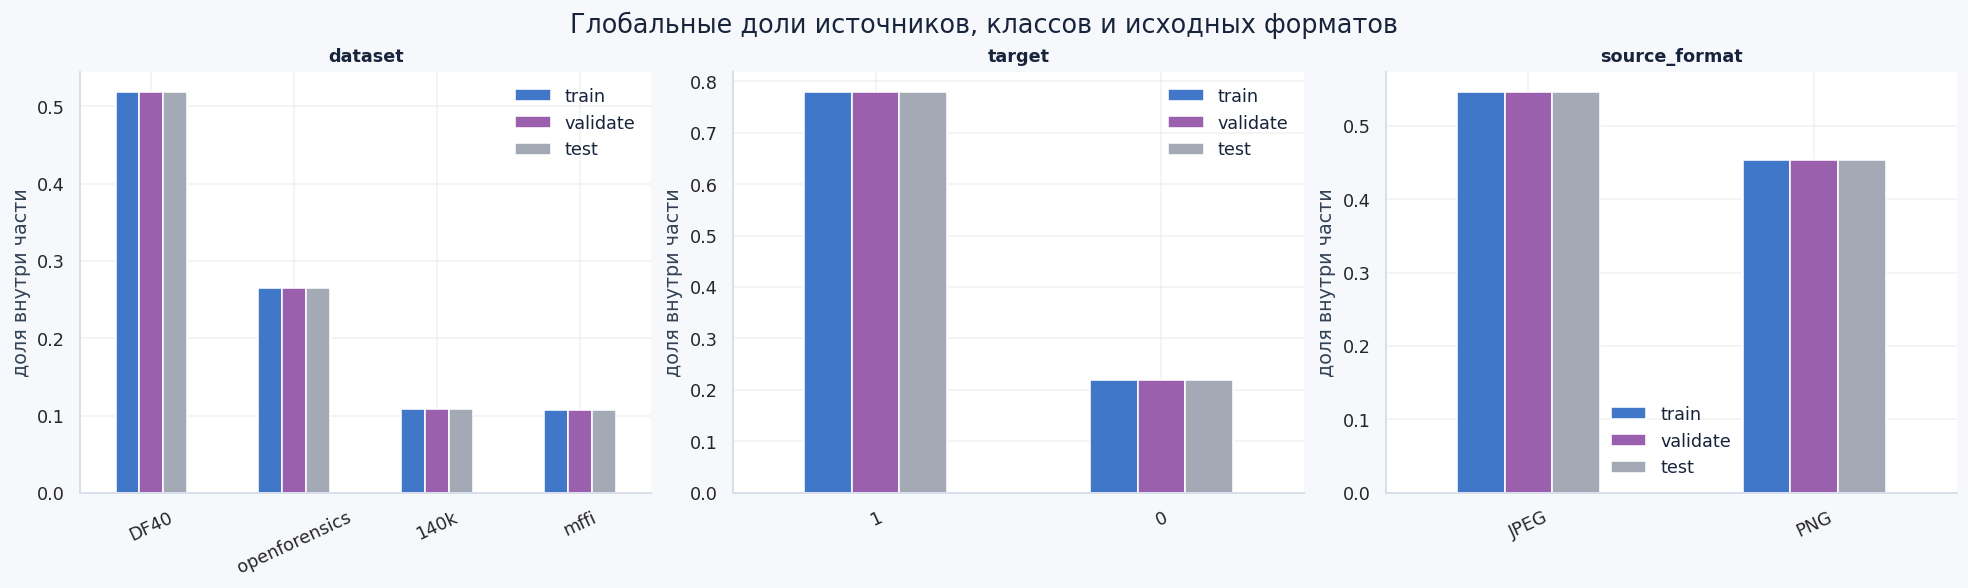

,pair,feature,TV,JS_bits,max_gap_pp
0,train / validate,dataset,0.0000,0.0000,0.00
1,train / validate,target,0.0000,0.0000,0.00
2,train / validate,generator,0.0001,0.0000,0.00
3,train / validate,manipulation,0.0000,0.0000,0.00
4,train / validate,domain,0.0001,0.0000,0.00
5,train / validate,source_format,0.0000,0.0000,0.00
6,train / validate,yaw_bin,0.0001,0.0000,0.00
7,train / validate,pitch_bin,0.0000,0.0000,0.00
8,train / validate,roll_bin,0.0001,0.0000,0.01
9,train / validate,light_bin,0.0000,0.0000,0.00


,author_baseline,global_balanced,изменение_строк
train,84205,128054,43849
validate,15676,27440,11764
test,83044,27440,-55604
excluded,18794,18785,-9


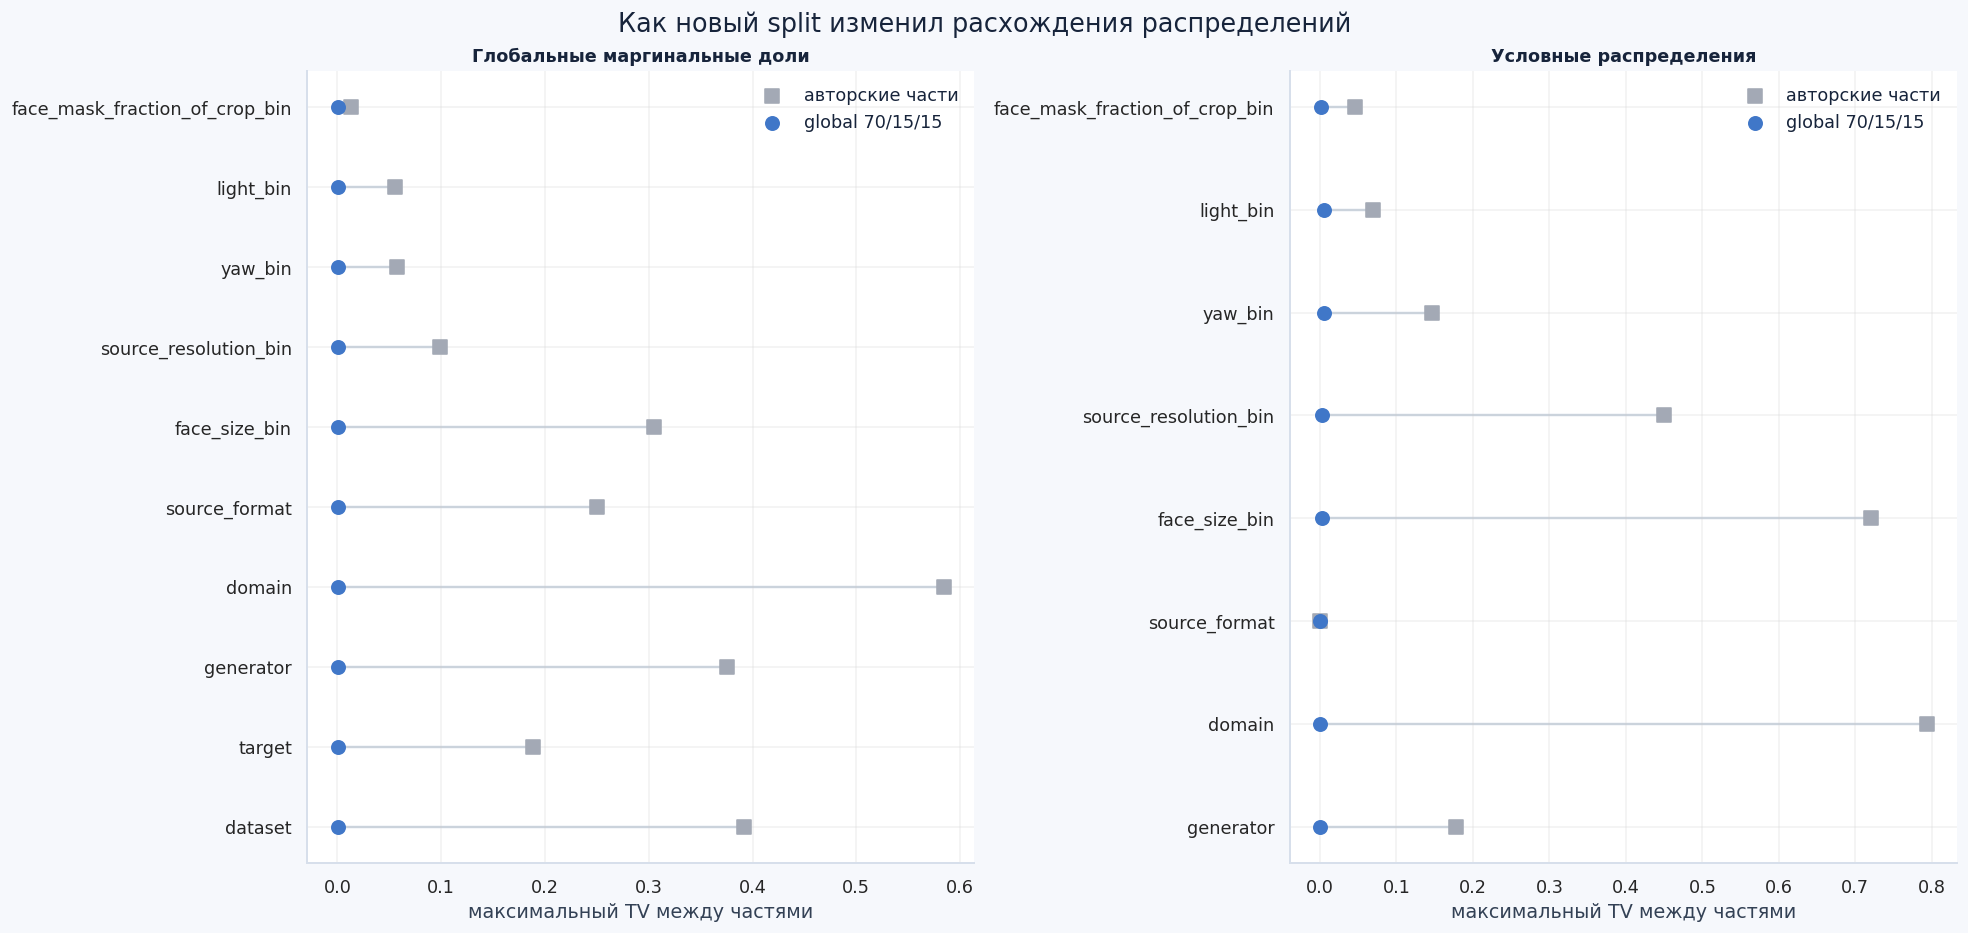

,version,scope,feature,comparisons,TV_mean,TV_max,max_gap_pp
14,author_baseline,conditional,domain,24,0.0780,0.7931,79.31
41,global_balanced,conditional,domain,24,0.0000,0.0004,0.04
15,author_baseline,conditional,face_mask_fraction_of_crop_bin,24,0.0160,0.0455,4.55
42,global_balanced,conditional,face_mask_fraction_of_crop_bin,24,0.0003,0.0009,0.09
16,author_baseline,conditional,face_size_bin,24,0.1721,0.7210,63.73
43,global_balanced,conditional,face_size_bin,24,0.0005,0.0026,0.26
17,author_baseline,conditional,generator,24,0.0149,0.1784,16.59
44,global_balanced,conditional,generator,24,0.0000,0.0002,0.01
18,author_baseline,conditional,light_bin,24,0.0254,0.0697,6.97
45,global_balanced,conditional,light_bin,24,0.0008,0.0057,0.57


version,author_baseline,global_balanced,TV_change
feature,,,
domain,0.5846,0.0001,-0.5845
dataset,0.3922,0.0000,-0.3921
generator,0.3754,0.0001,-0.3753
face_size_bin,0.3046,0.0000,-0.3045
manipulation,0.3010,0.0000,-0.3010
source_format,0.2497,0.0000,-0.2497
target,0.1888,0.0000,-0.1888
source_resolution_bin,0.0988,0.0000,-0.0988
yaw_bin,0.0574,0.0001,-0.0573


In [17]:
E.plot_global_marginals(parts)
plt.show()
global_divergences = E.global_split_divergences(parts)
display(global_divergences.style.format({"TV": "{:.4f}", "JS_bits": "{:.4f}", "max_gap_pp": "{:.2f}"}))
baseline_path = ROOT / "data/splits/author_baseline"
if (baseline_path / "audit.json").is_file():
    baseline_parts, baseline_audit = E.load_composite(ROOT, "data/splits/author_baseline")
    count_comparison = pd.DataFrame({
        "author_baseline": {name: len(frame) for name, frame in baseline_parts.items()},
        "global_balanced": {name: len(frame) for name, frame in parts.items()},
    })
    count_comparison["изменение_строк"] = count_comparison["global_balanced"] - count_comparison["author_baseline"]
    display(count_comparison)
    before_after = E.balance_before_after(baseline_parts, parts)
    E.plot_balance_before_after(before_after)
    plt.show()
    display(before_after.sort_values(["scope", "feature", "version"]).style.format({
        "TV_mean": "{:.4f}", "TV_max": "{:.4f}", "max_gap_pp": "{:.2f}",
    }))
    global_shift = before_after.loc[before_after["scope"].eq("global")].pivot(
        index="feature", columns="version", values="TV_max",
    )
    global_shift["TV_change"] = global_shift["global_balanced"] - global_shift["author_baseline"]
    display(global_shift.sort_values("TV_change").style.format("{:.4f}"))
else:
    display(Markdown("Сохранённого author_baseline нет; глобальные распределения нового split рассчитаны выше. Для before/after нужен metadata snapshot прежней сборки."))

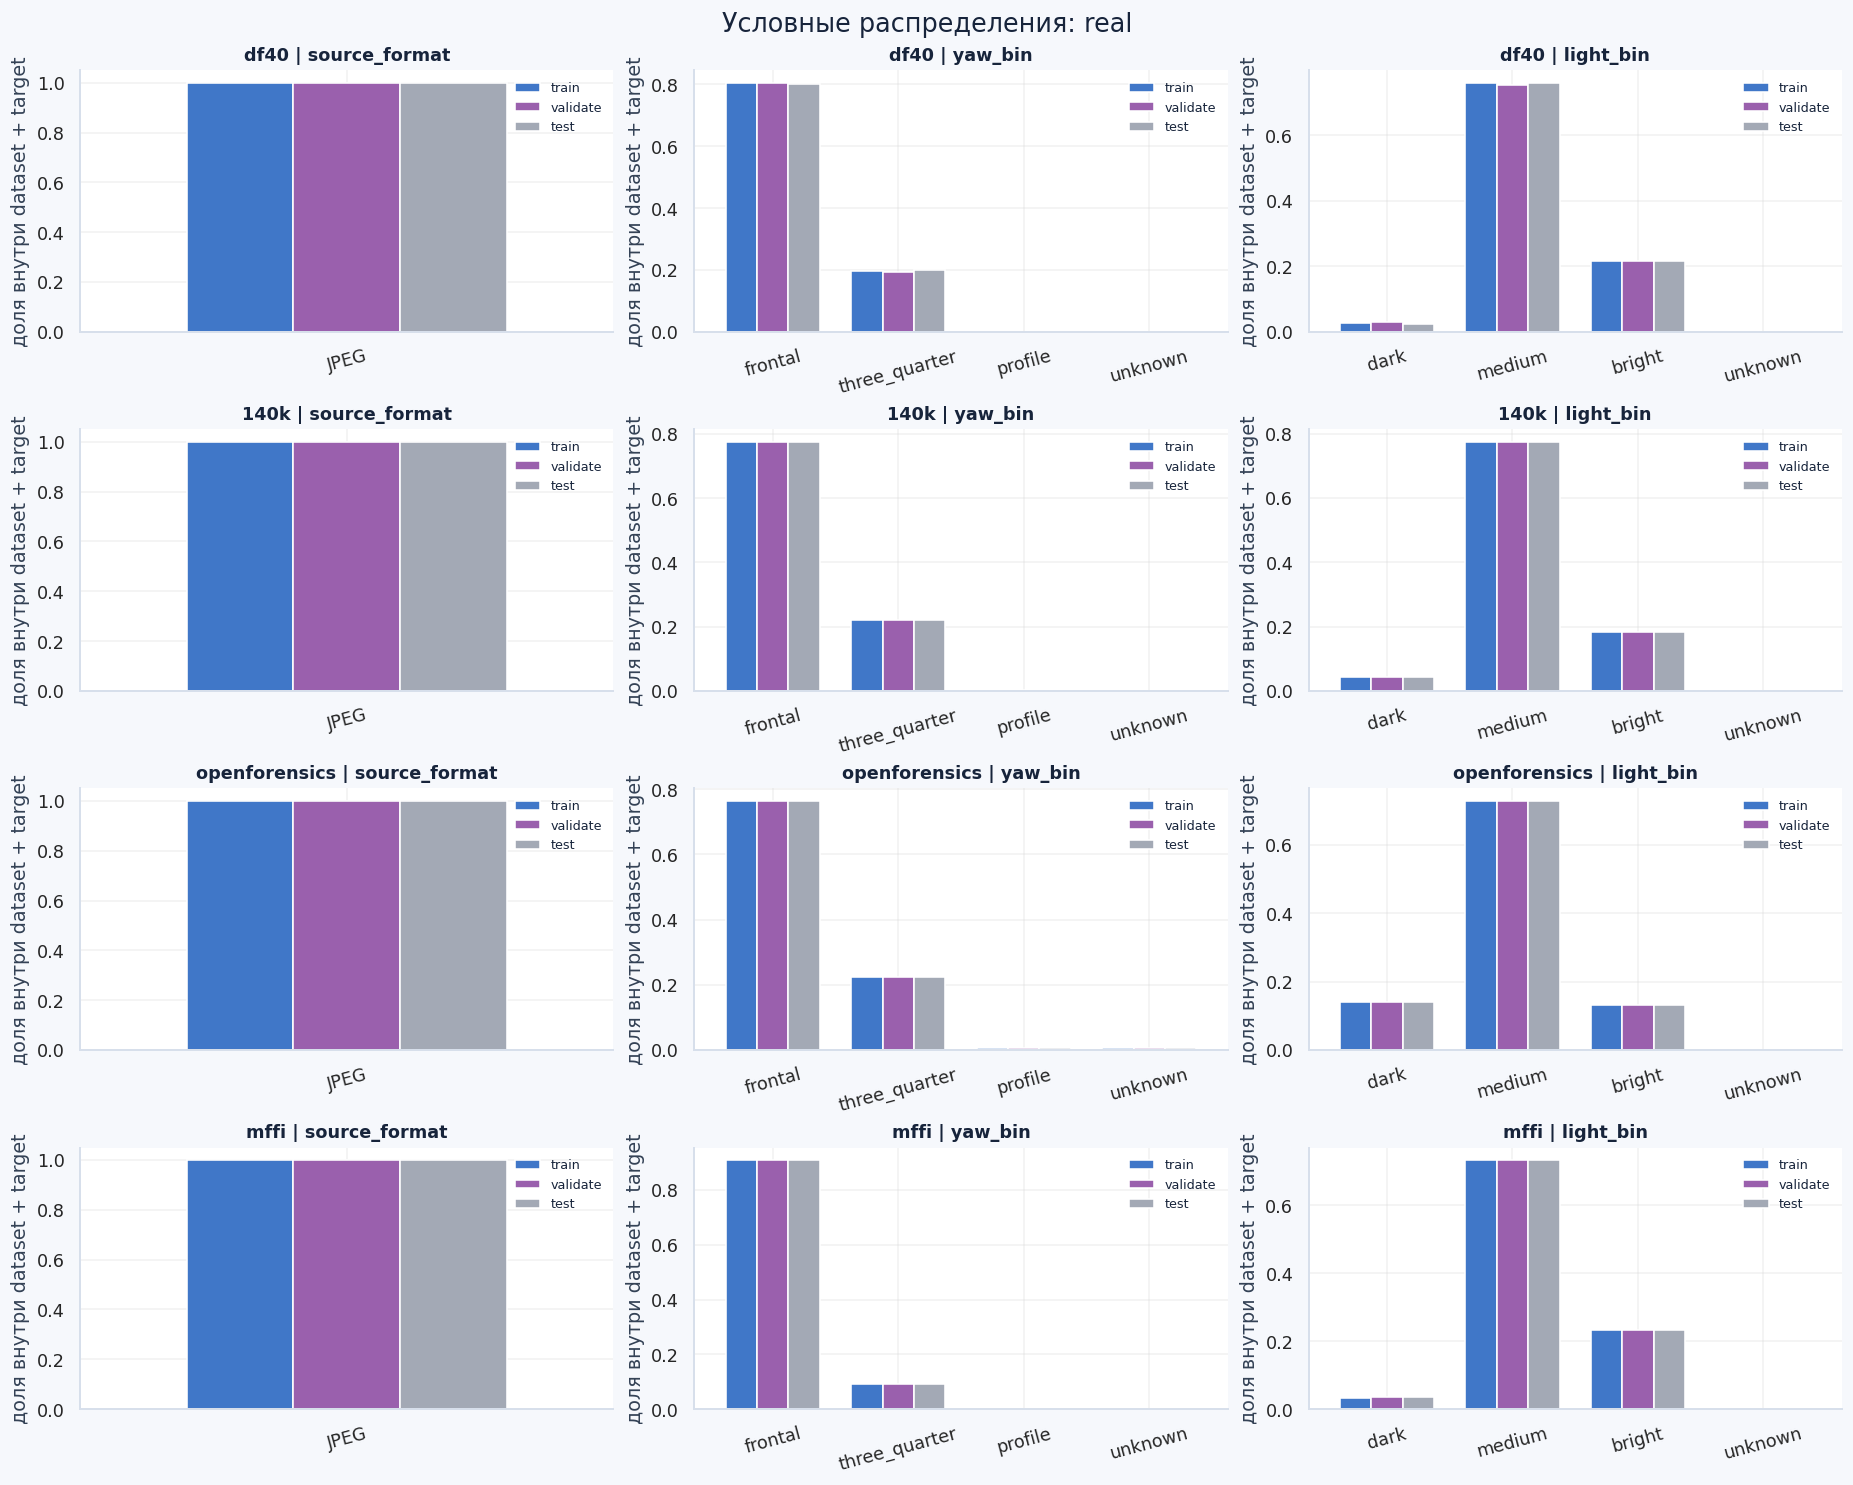

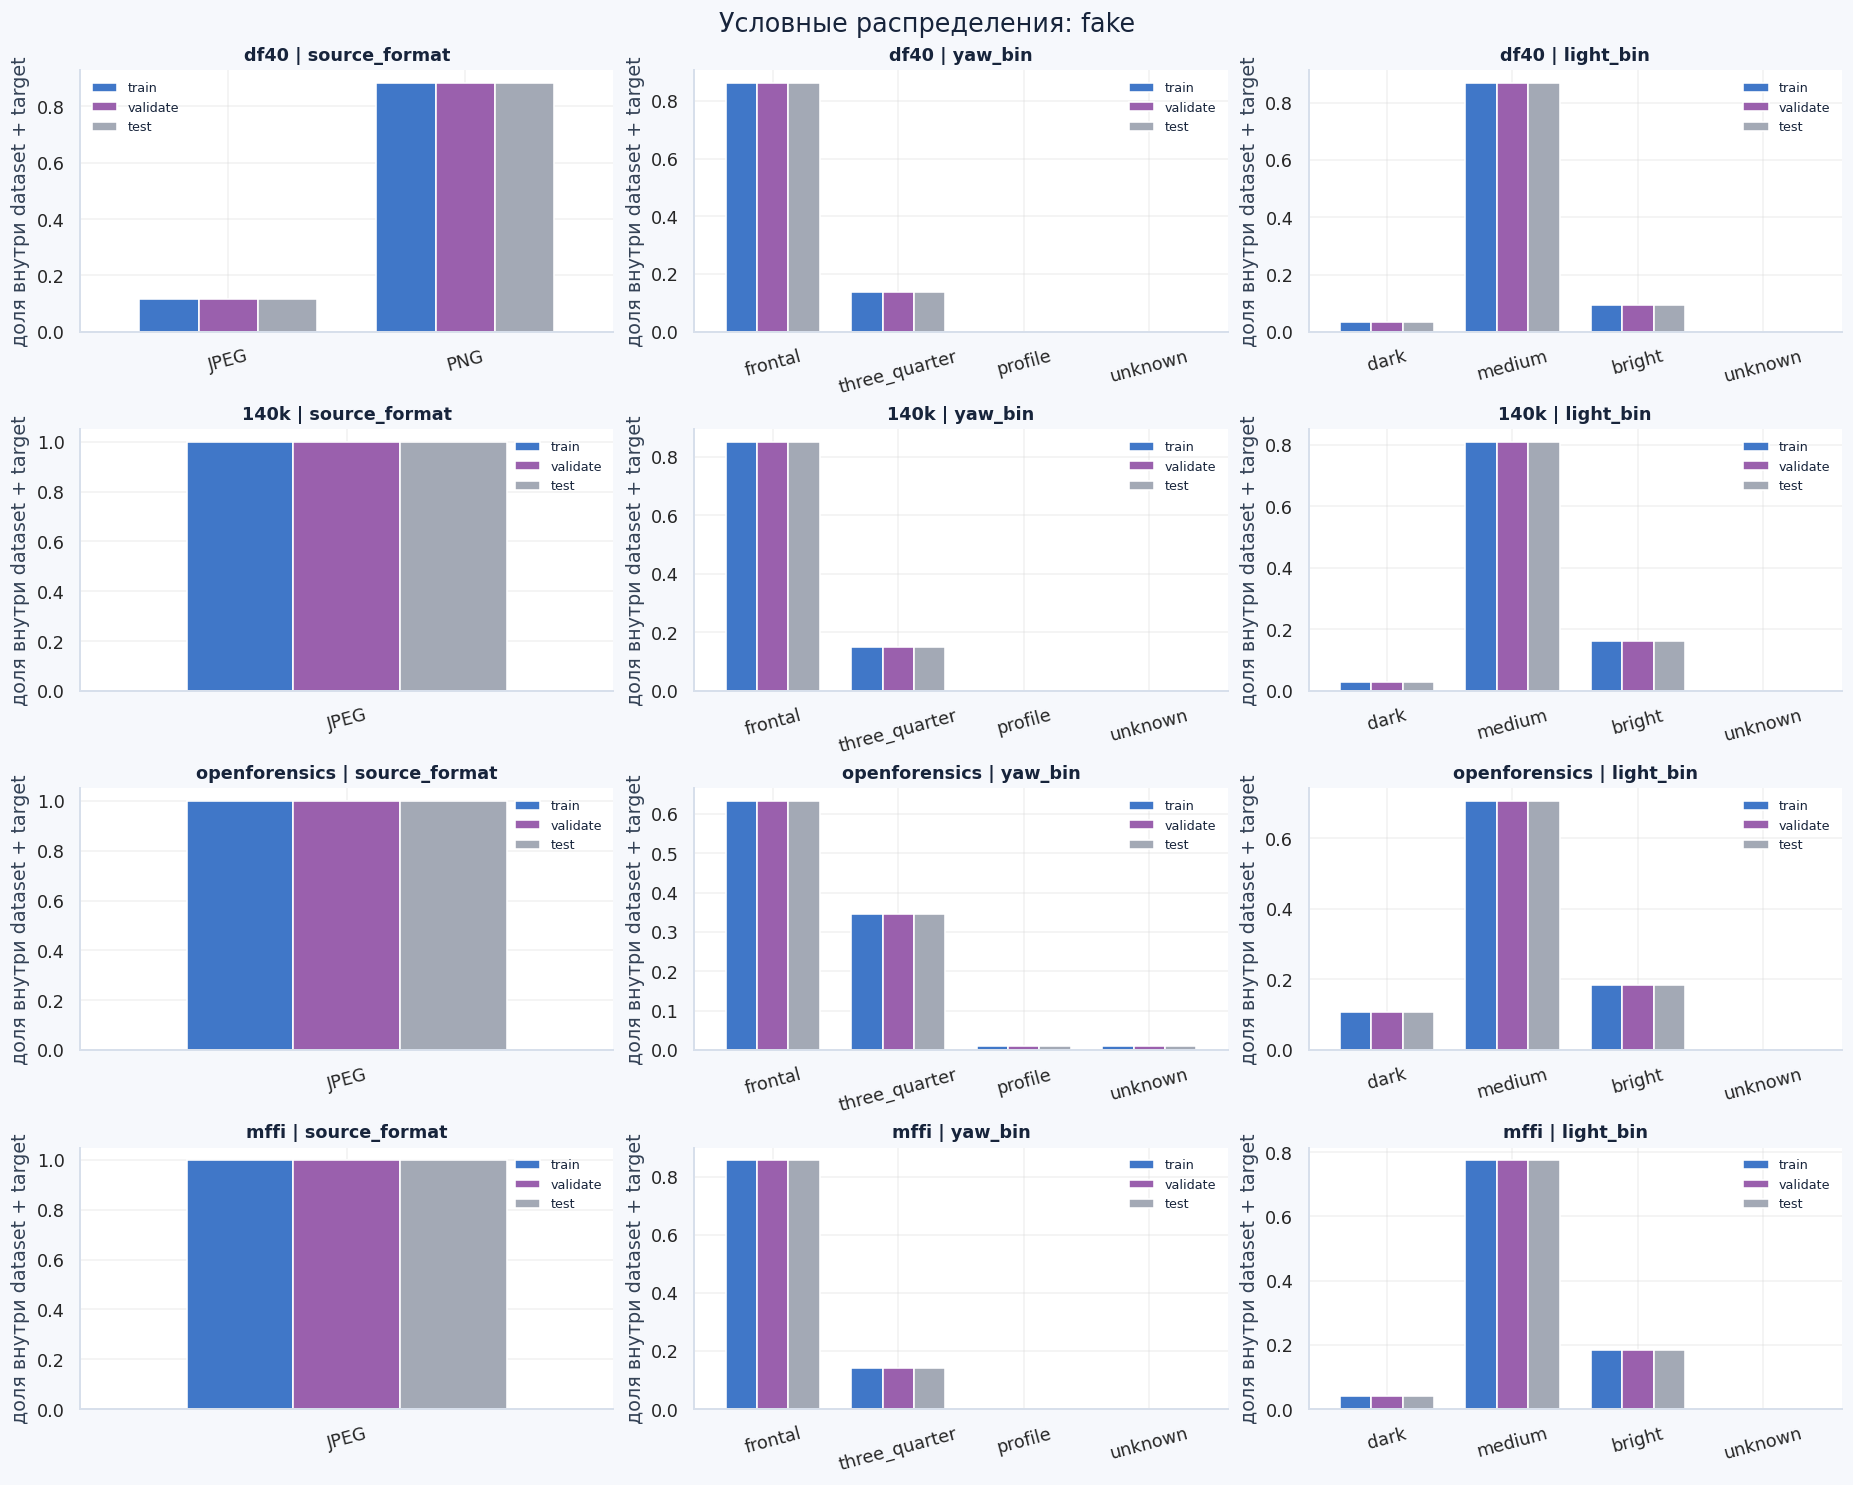

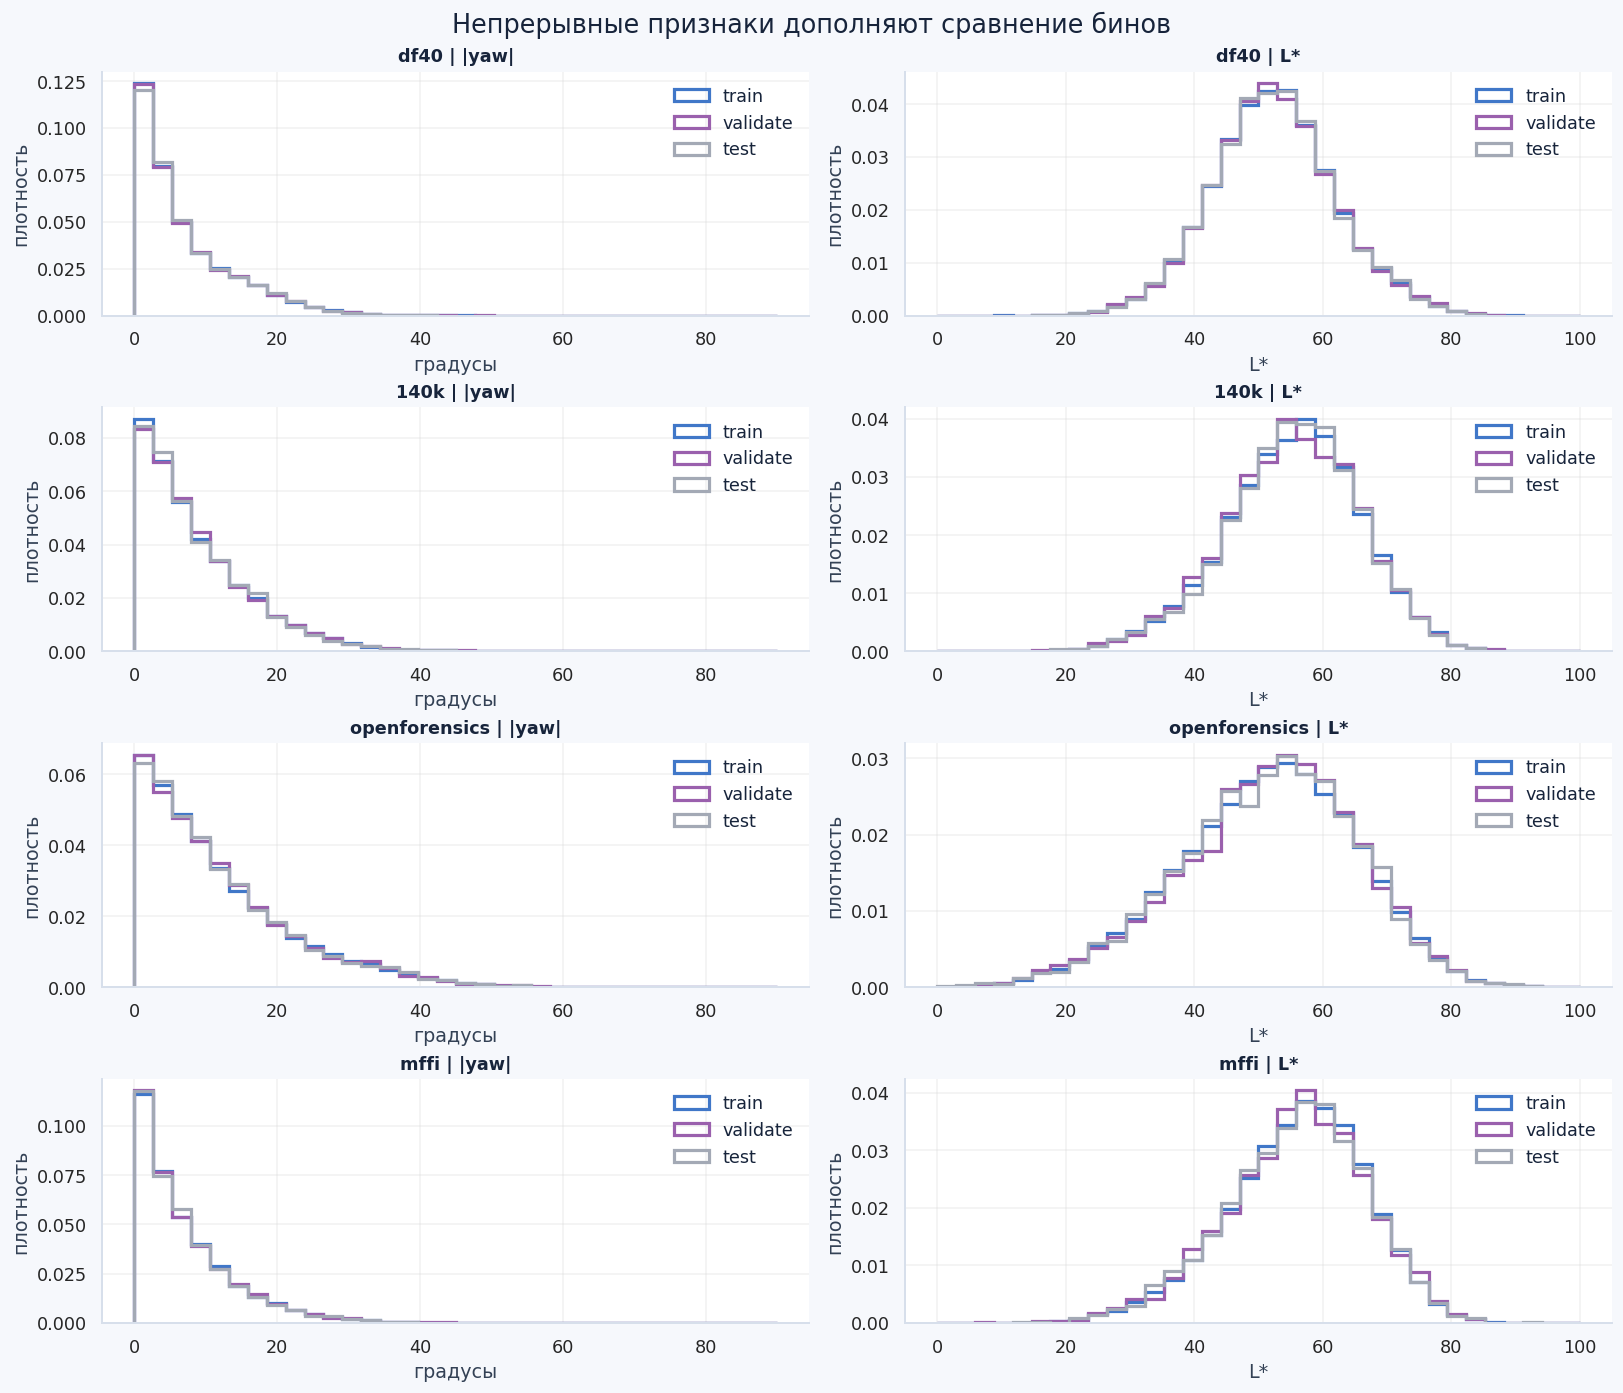

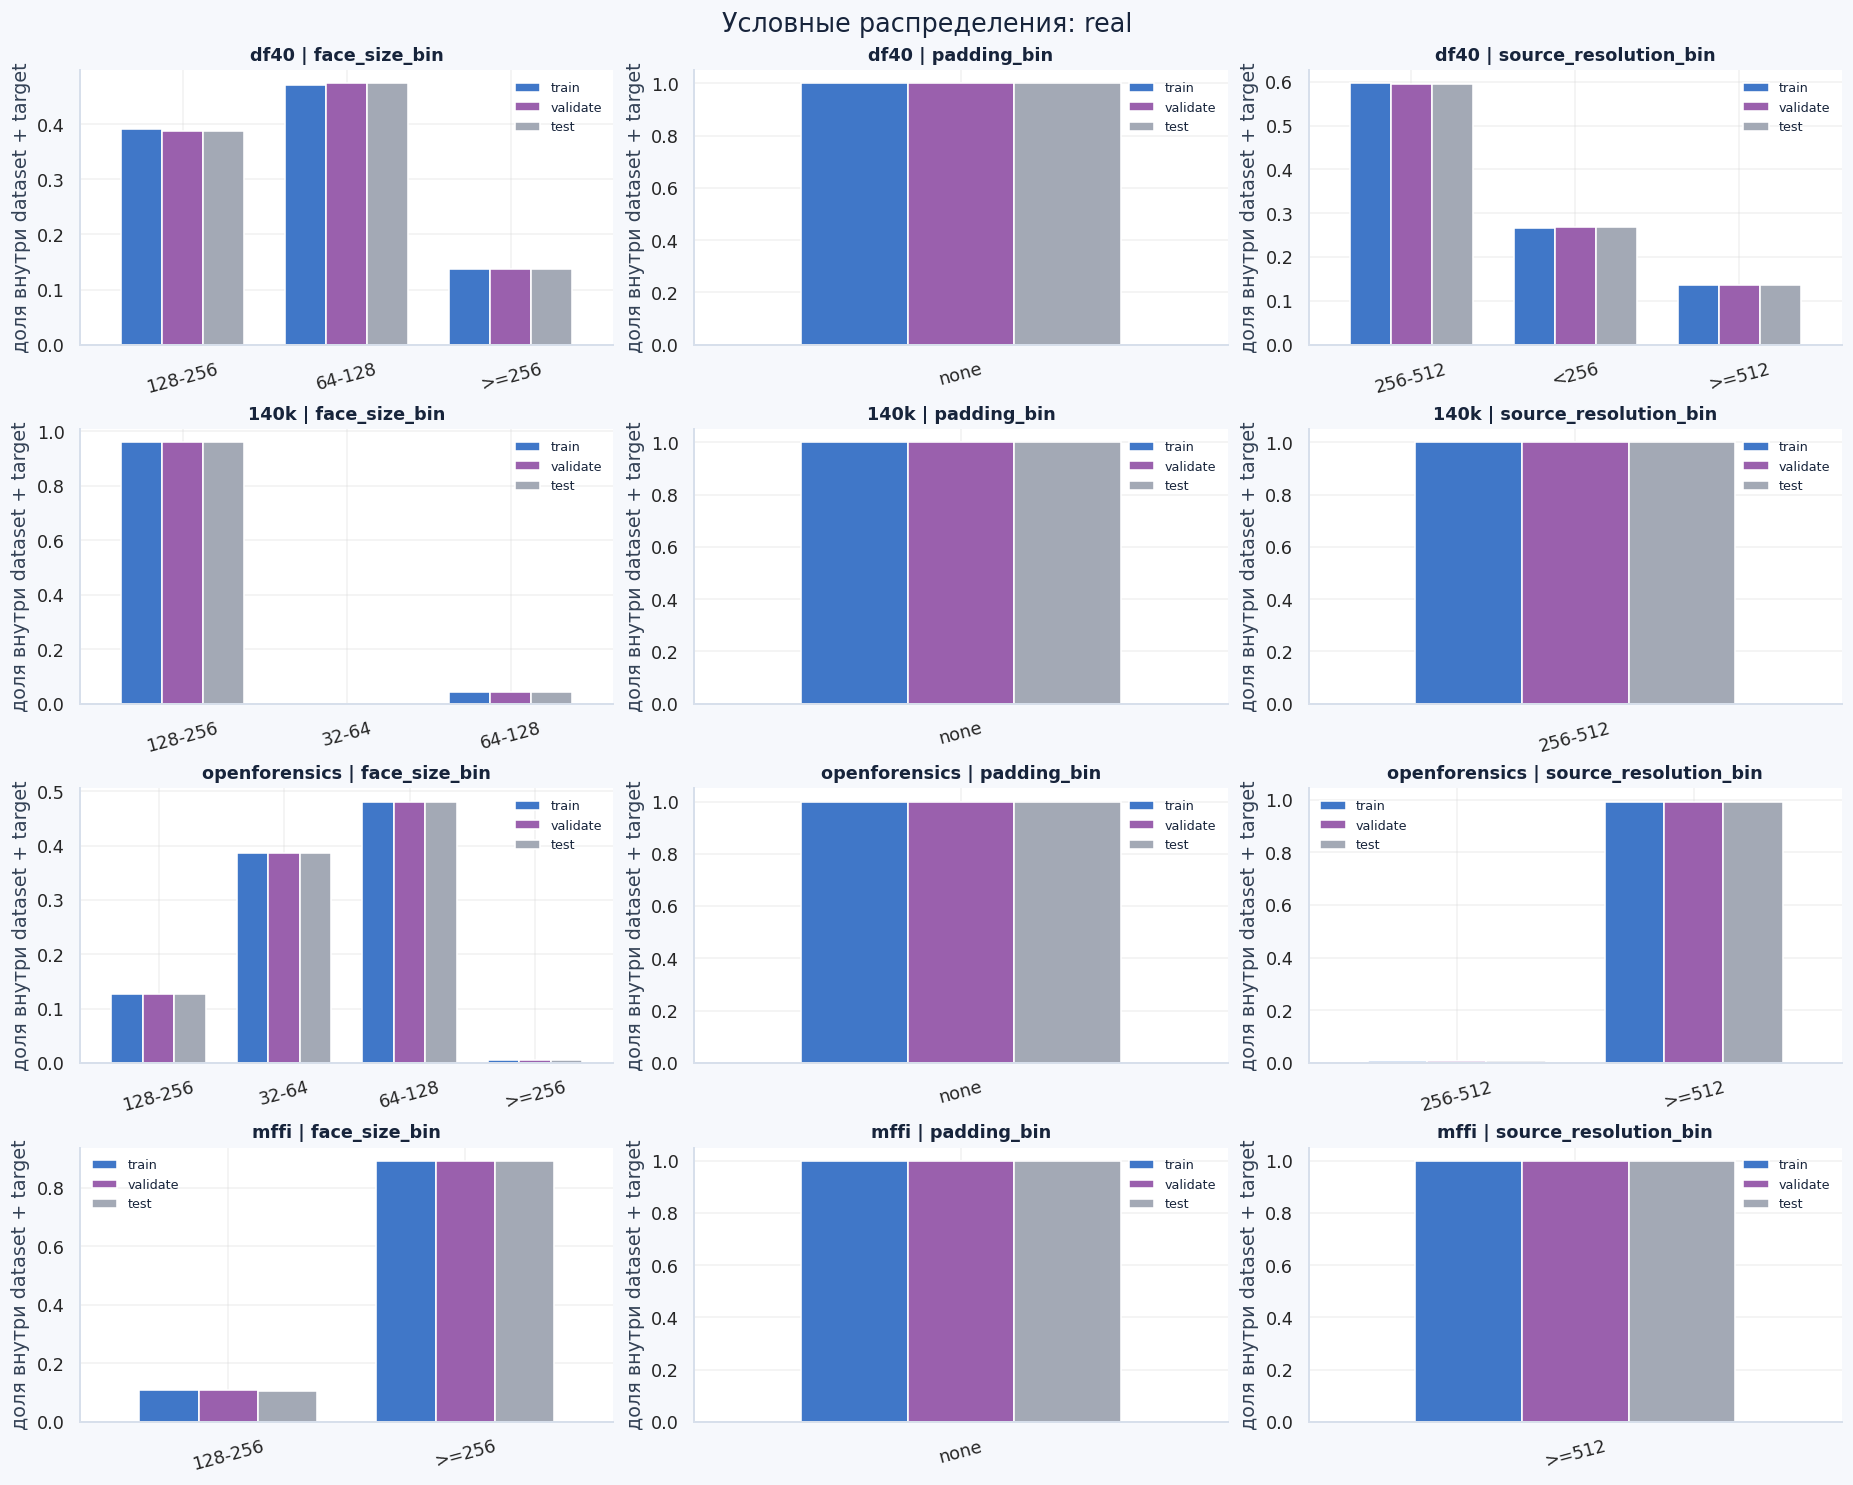

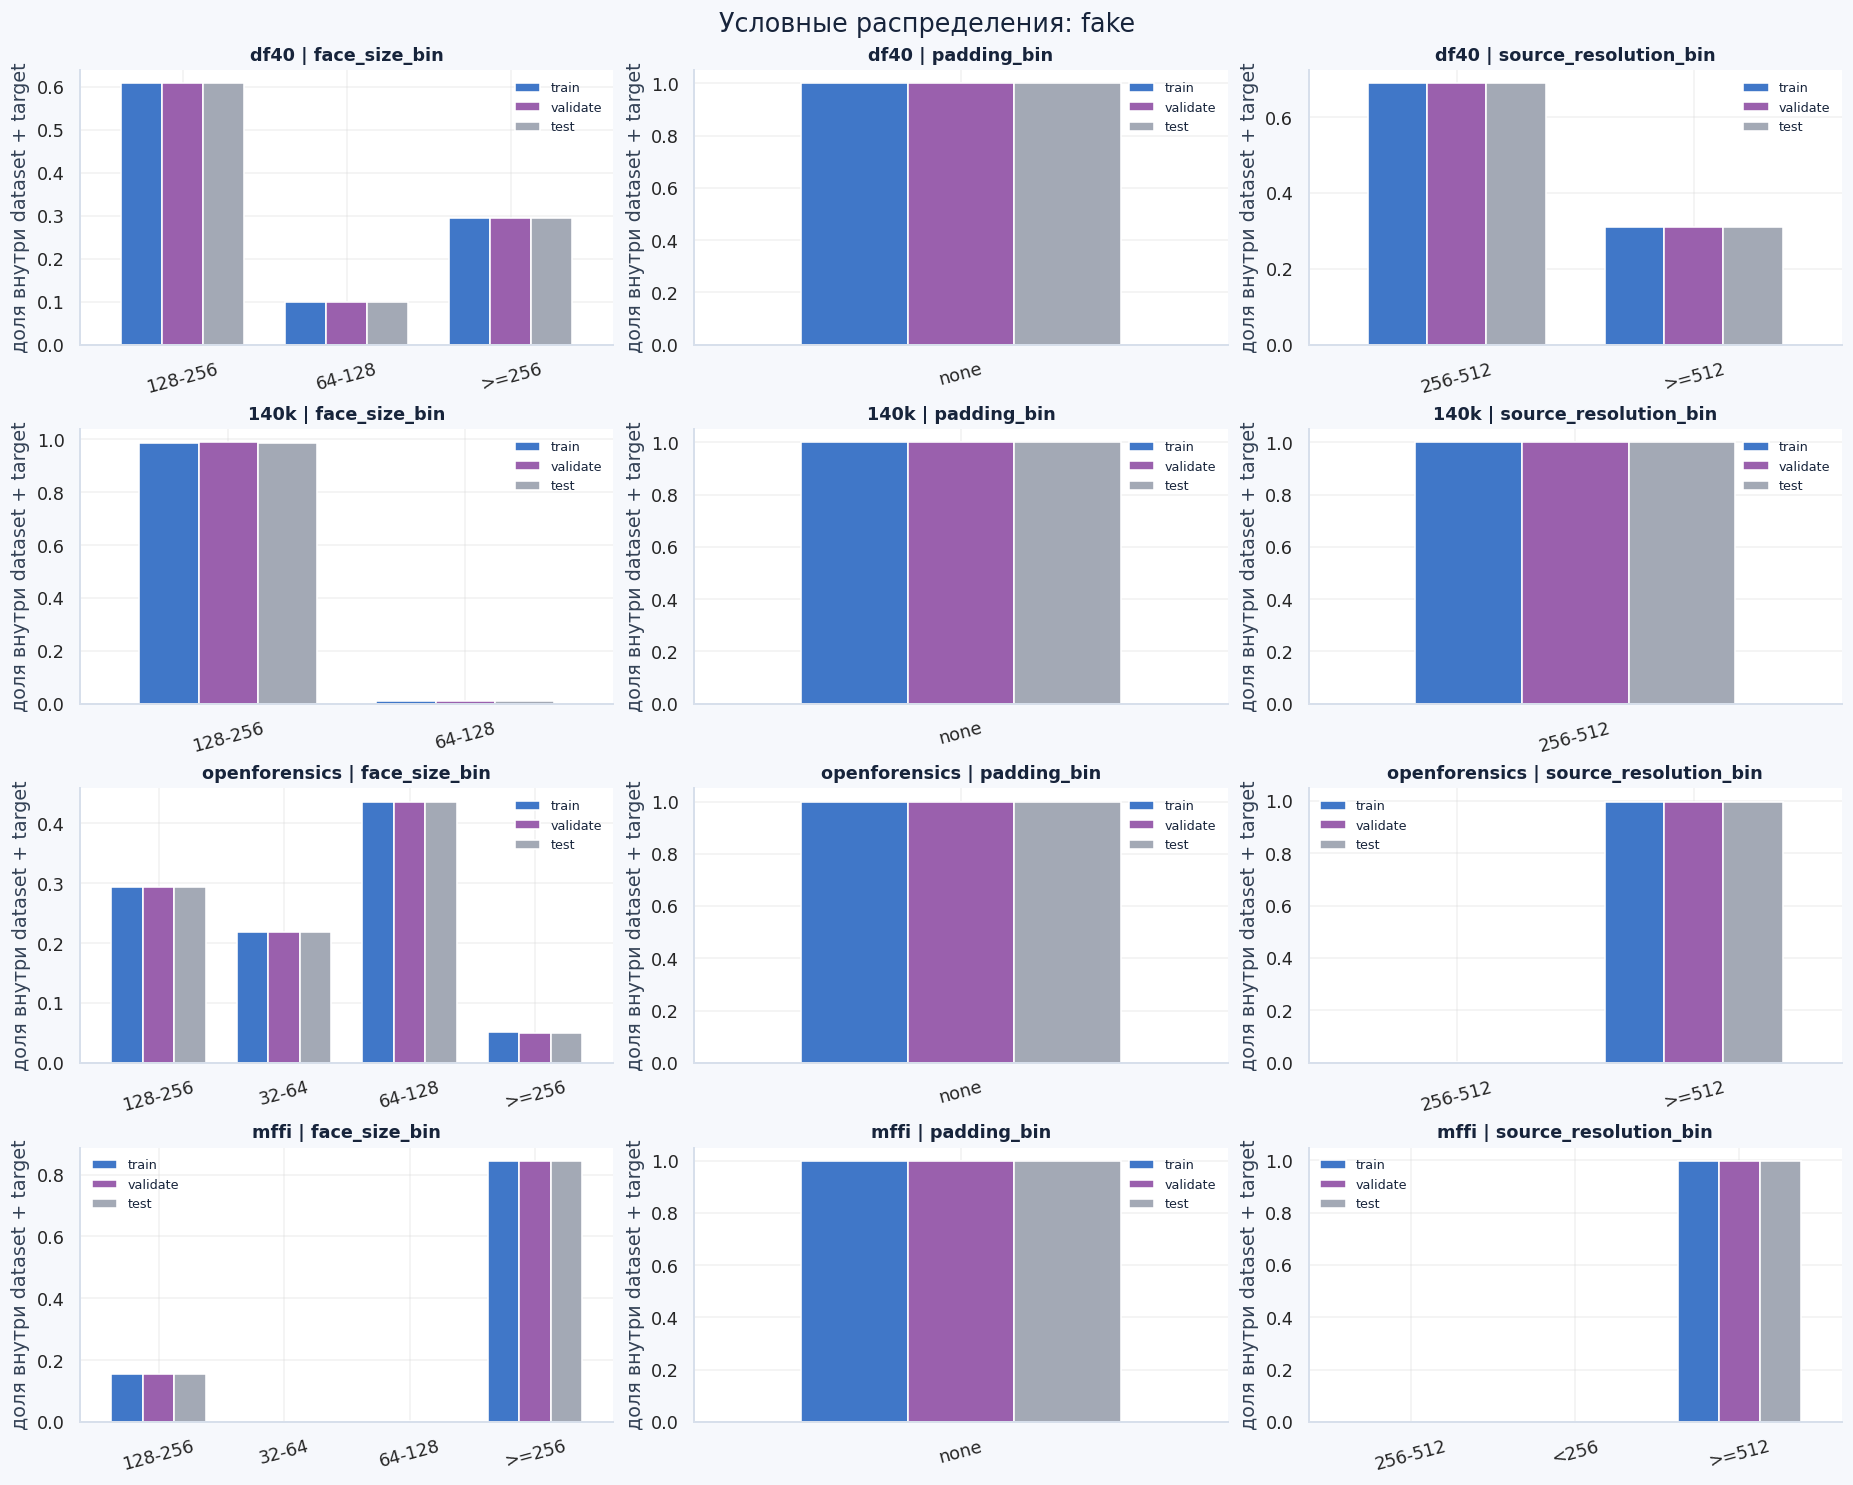

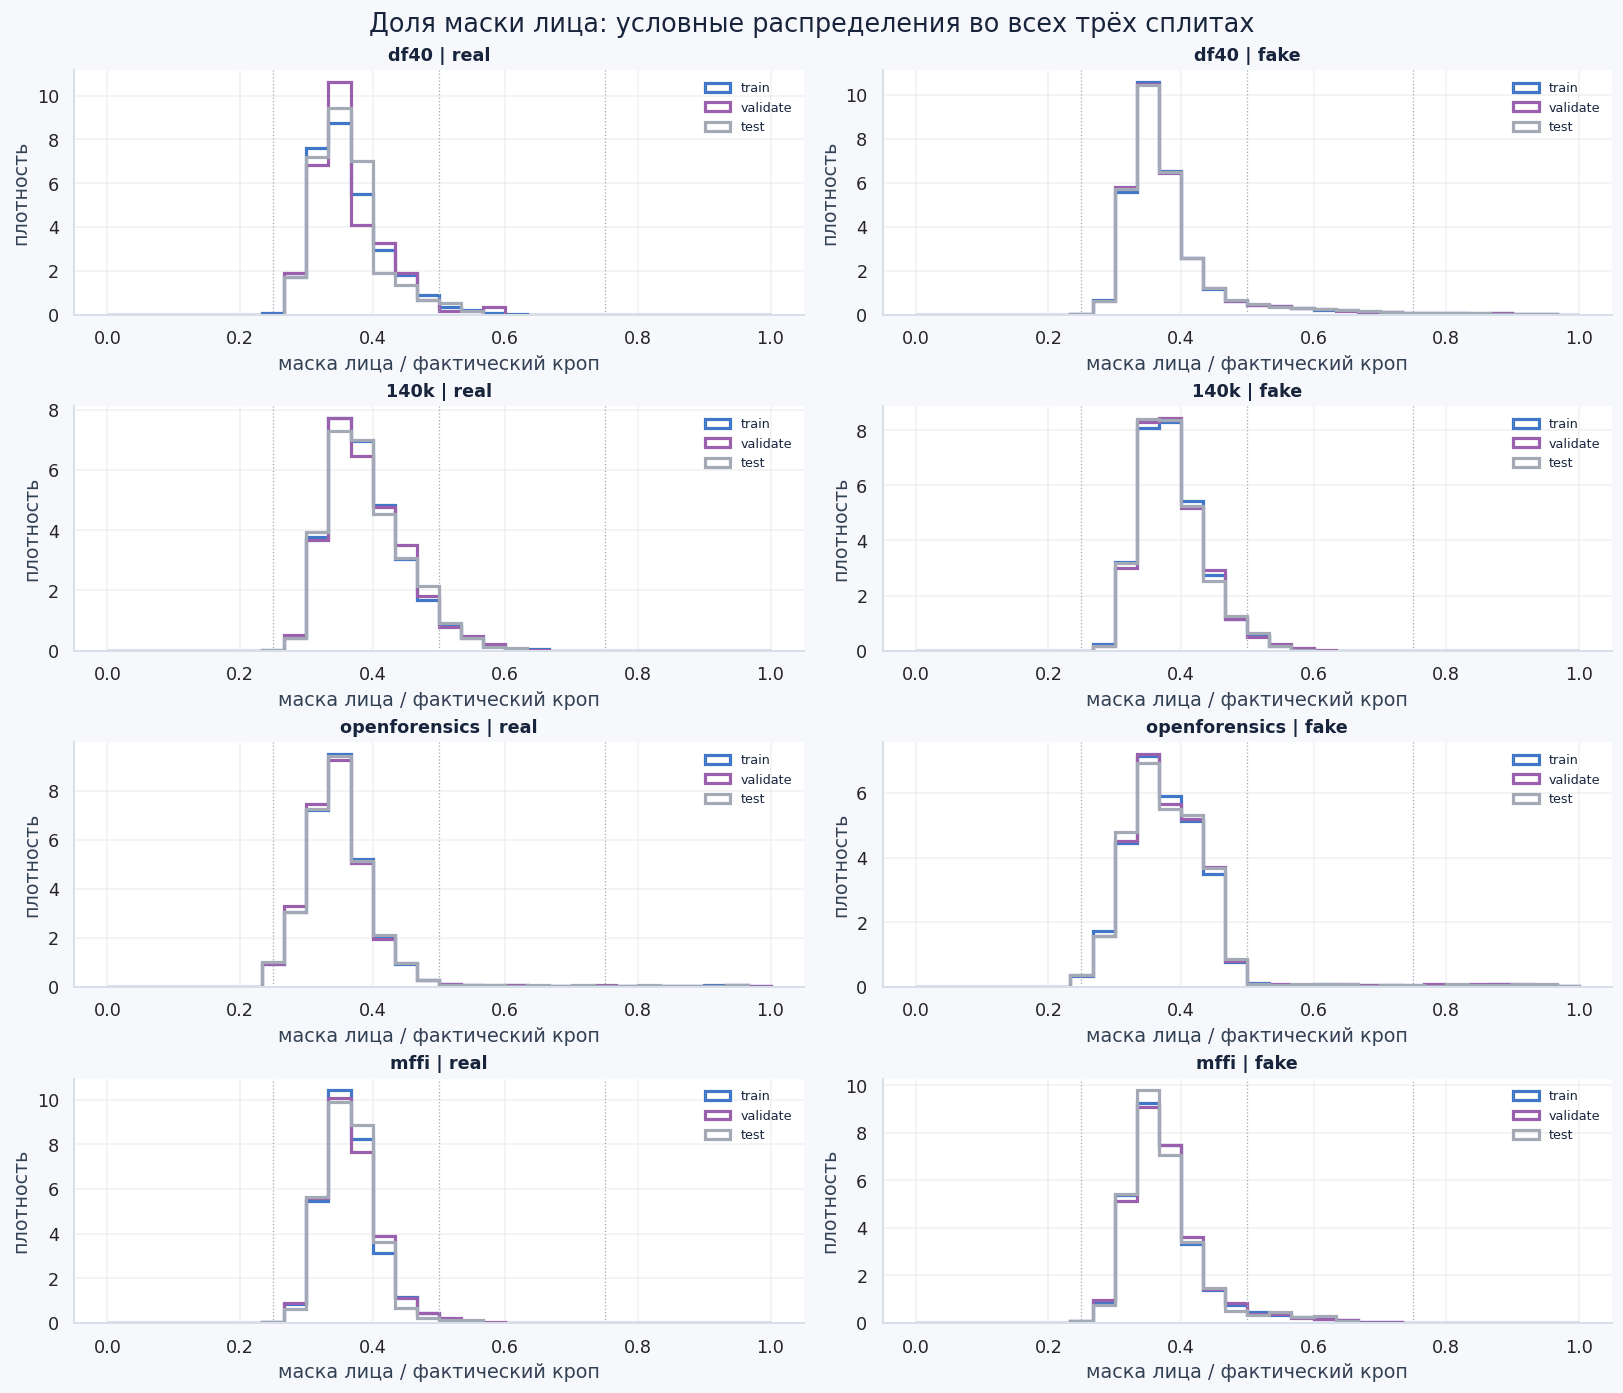

final_split                                          train  validate   test
dataset       target face_mask_fraction_of_crop_bin                        
140k          0      [0.25,0.5)                       6596      1414   1414
                     [0.5,0.75)                        361        77     77
              1      [0.25,0.5)                       6800      1457   1458
                     [0.5,0.75)                        198        43     42
DF40          0      [0.25,0.5)                        800       171    171
                     [0.5,0.75)                         18         4      4
              1      [0.25,0.5)                      60727     13012  13012
                     [0.5,0.75)                       4154       890    890
                     [0.75,1]                          797       171    171
mffi          0      [0.25,0.5)                       4568       979    979
                     [0.5,0.75)                         45        10     10
              1      [0.25,0.5)                       8689      1863   1862
                     [0.5,0.75)                        422        90     90
                     [0.75,1]                            7         1      2
openforensics 0      [0.25,0.5)                      15405      3301   3302
                     [0.5,0.75)                        231        49     49
                     [0.75,1]                          165        36     35
              1      [0.25,0.5)                      17481      3745   3745
                     [0.5,0.75)                        320        69     69
                     [0.75,1]                          270        58     58

In [18]:
E.plot_conditional_bins(parts, target=0)
plt.show()
E.plot_conditional_bins(parts, target=1)
plt.show()
E.plot_split_continuous(parts)
plt.show()
geometry_features = ("face_size_bin", "padding_bin", "source_resolution_bin")
E.plot_conditional_bins(parts, target=0, features=geometry_features)
plt.show()
E.plot_conditional_bins(parts, target=1, features=geometry_features)
plt.show()
E.plot_split_mask_fraction(parts)
plt.show()
display(pd.crosstab([composition["dataset"], composition["target"], composition["face_mask_fraction_of_crop_bin"]], composition["final_split"]).reindex(columns=["train", "validate", "test"], fill_value=0))

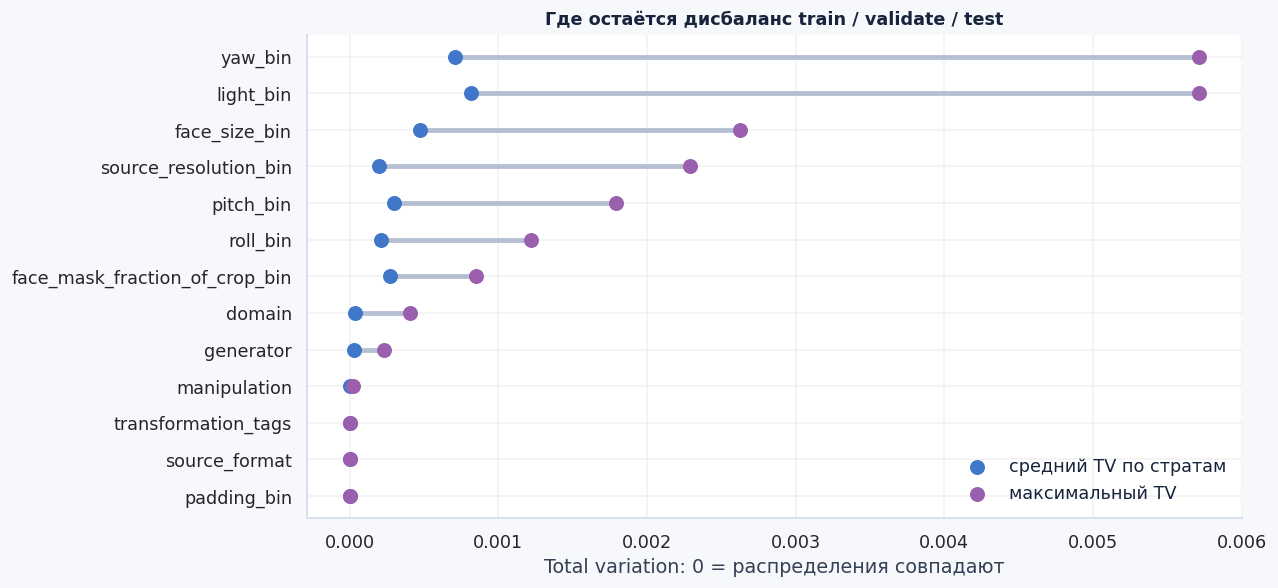

,dataset,target,feature,pair,left_n,right_n,TV,JS_bits,max_gap_pp,generator,tag
290,DF40,0,yaw_bin,validate / test,175,175,0.006,0.000,0.6,nan,nan
314,DF40,0,light_bin,validate / test,175,175,0.006,0.000,0.6,nan,nan
74,DF40,0,light_bin,train / validate,818,175,0.005,0.000,0.5,nan,nan
170,DF40,0,yaw_bin,train / test,818,175,0.003,0.000,0.3,nan,nan
194,DF40,0,light_bin,train / test,818,175,0.003,0.000,0.3,nan,nan
202,DF40,0,face_size_bin,train / test,818,175,0.003,0.000,0.3,nan,nan
82,DF40,0,face_size_bin,train / validate,818,175,0.003,0.000,0.3,nan,nan
50,DF40,0,yaw_bin,train / validate,818,175,0.003,0.000,0.3,nan,nan
98,DF40,0,source_resolution_bin,train / validate,818,175,0.002,0.000,0.2,nan,nan
218,DF40,0,source_resolution_bin,train / test,818,175,0.002,0.000,0.2,nan,nan


Страт без одной из сравниваемых частей: **0**.

,dataset,target,feature,pair,left_n,right_n,TV,JS_bits,max_gap_pp,generator,tag


In [19]:
divergences = E.split_divergences(parts)
E.plot_divergences(divergences)
plt.show()
summary = divergences.groupby(["pair", "feature"]).agg(
    сравнимых_страт=("TV", "count"),
    TV_средний=("TV", "mean"),
    TV_максимум=("TV", "max"),
    JS_средний=("JS_bits", "mean"),
)
display(summary.style.format(precision=3))
display(
    divergences.sort_values("TV", ascending=False).head(25)
    .style.format({"TV": "{:.3f}", "JS_bits": "{:.3f}", "max_gap_pp": "{:.1f}"})
)
unsupported = divergences.loc[divergences["left_n"].eq(0) | divergences["right_n"].eq(0)]
display(Markdown(f"Страт без одной из сравниваемых частей: **{len(unsupported):,}**."))
display(unsupported.head(30))

## 11. Проверка утечек и итоговые исключения

Здесь независимо пересчитываем пересечения source-групп и точных хешей между train, validate и test. Ноль по этим ключам подтверждает отсутствие найденных пересечений. Полную identity-независимость без полной identity-разметки подтвердить нельзя.

Для pHash показываем исходы дополнительной проверки пикселей. Единица этого отчёта - пара кандидатов, а не уникальное лицо: одна строка может входить в несколько пар. Верифицированные связи участвуют в группировке, отклонённые связи её не создают. Недоступные проверки отдельно учитываются в исключениях. Пороги являются эвристикой близости изображений, а не гарантией нахождения всех возможных копий.

,групп,между сплитами,без ключа
ключ,,,
group_id,147727,0,0
image_sha256,153158,0,0
decoded_sha256,153158,0,0
crop_sha256,182934,0,0


,outcome,pairs,share
0,подтверждены пикселями / точным хешем,5576,3.9%
1,отклонены проверкой,139241,96.1%
2,нет доступной совместимой пары изображений,0,0.0%


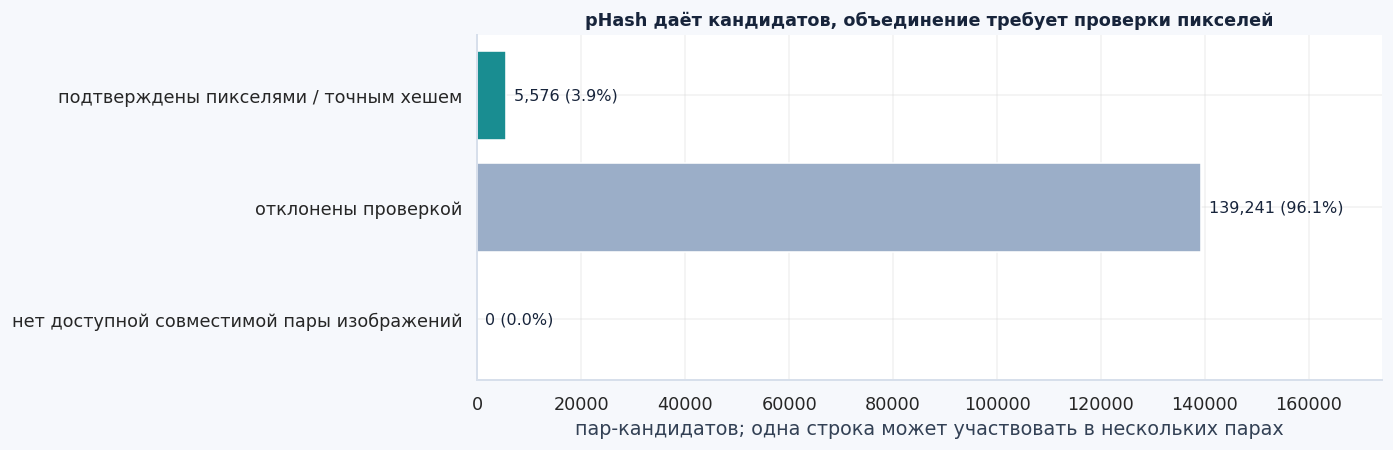

,metric,count,unit
0,все пары-кандидаты pHash,144817,пар
1,подтверждены точным хешем,4912,пар
2,подтверждены по исходнику,448,пар
3,подтверждены по кропу,216,пар
4,отклонены с low-texture условием,172,пар
5,строки без доступного сравнения,0,строк
6,исключены из-за недоступной проверки,0,строк


,value
aspect_ratio_tolerance,0.020
cache_size,512
comparison_order,"[crop, original]"
min_gray_std,0.031
min_laplacian_variance,4.000
opencv_threads,1
rgb_mae_max,0.020
ssim_min,0.950
ssim_sigma,1.500
ssim_space,RGB


,verification execution
execution_mode,reused_cache
verified_now,False


,количество
конфликтующих точных crop SHA (строк),0
конфликтующих совпавших лиц (строк),0
удалено на авторских границах (строк),0
удалено точных копий лица (строк),4743
без известной identity (строк),201719
наибольшая связанная группа (строк),45


,lineage policy
version,3
df40_records,100086
changed_source_records,0
efs_unit,generated_image_unknown_identity
generation_batch_is_grouping_key,False
generic_e4e_inversions_unit,edited_image_unknown_identity
unverified_fe_unit,edited_image_unknown_identity
explicit_source_identifiers_preserved,True


,source_group_basis,lineage_status,processing_records,source_groups,known_identity_records,generation_batches_audit_only
1,generated_image_unknown_identity,unknown,87838,87753,0,16946
0,edited_image_unknown_identity,unknown,5805,5805,0,166
3,published_source_identifier,source_identifier,5155,995,0,995
2,native_real_serial_unknown_identity,unknown,1288,1287,0,0


source_groups и generation_batches - технические группы источников и батчей, а не число людей. generation_batch не используется как ключ разбиения.

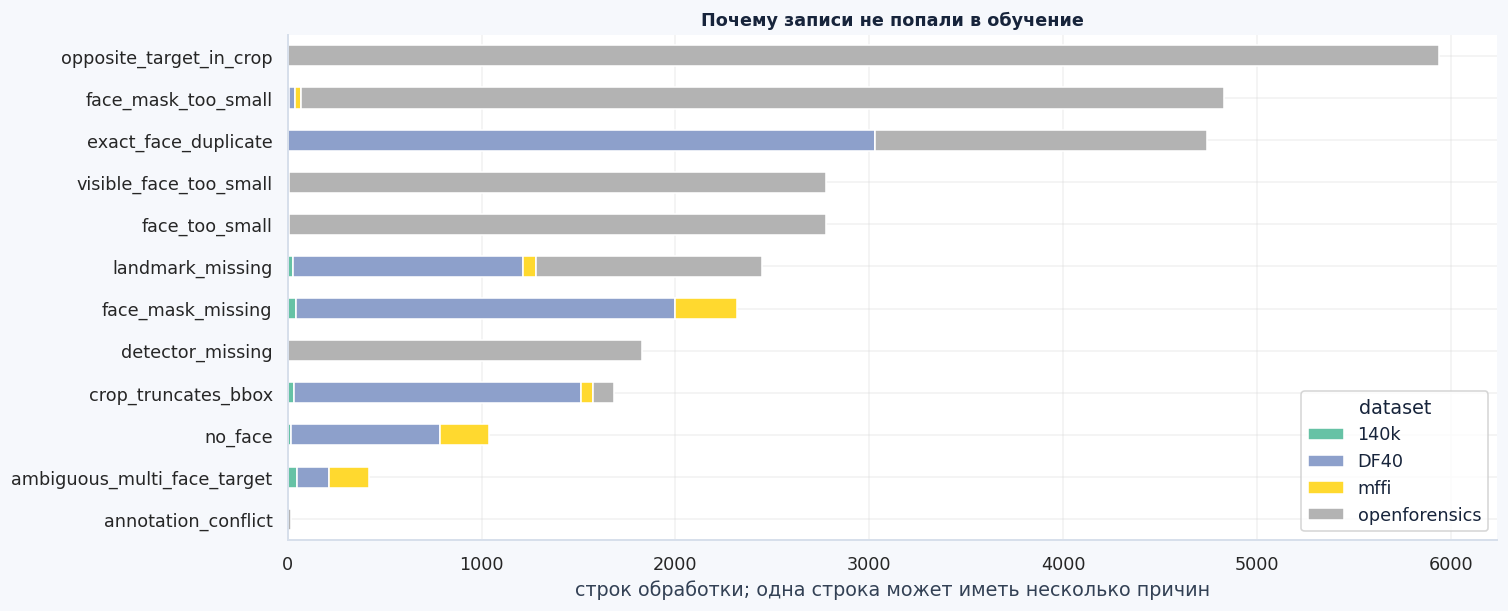

,dataset,reason,records
24,openforensics,opposite_target_in_crop,5942
25,openforensics,face_mask_too_small,4766
8,DF40,exact_face_duplicate,3028
27,openforensics,visible_face_too_small,2775
26,openforensics,face_too_small,2775
9,DF40,face_mask_missing,1956
28,openforensics,detector_missing,1829
29,openforensics,exact_face_duplicate,1714
10,DF40,crop_truncates_bbox,1480
11,DF40,landmark_missing,1187


In [20]:
overlaps = E.overlap_audit(parts)
display(overlaps)
assert overlaps["между сплитами"].eq(0).all()
duplicate_diagnostics = E.near_duplicate_audit(composite_audit)
display(duplicate_diagnostics["outcomes"].style.format({"share": "{:.1%}"}))
E.plot_near_duplicate_audit(duplicate_diagnostics["outcomes"])
plt.show()
display(duplicate_diagnostics["details"])
display(duplicate_diagnostics["settings"])
display(pd.Series({key: composite_audit["near_duplicate_verification"].get(key)
                   for key in ("execution_mode", "verified_now")}, name="verification execution").to_frame())
display(pd.Series({
    "конфликтующих точных crop SHA (строк)": composite_audit["contradictory_crop_rows"],
    "конфликтующих совпавших лиц (строк)": composite_audit.get("matched_face_conflict_rows", 0),
    "удалено на авторских границах (строк)": composite_audit["author_overlap_removed"],
    "удалено точных копий лица (строк)": composite_audit["exact_face_duplicates_removed"],
    "без известной identity (строк)": composite_audit["unknown_identity_rows"],
    "наибольшая связанная группа (строк)": composite_audit["largest_group"],
}, name="количество").to_frame())
display(pd.Series(composite_audit.get("df40_lineage_policy", {}), name="lineage policy").to_frame())
lineage_records = pd.concat(list(parts.values()), ignore_index=True)
display(E.lineage_table(lineage_records))
display(Markdown("source_groups и generation_batches - технические группы источников и батчей, а не число людей. generation_batch не используется как ключ разбиения."))
exclusions = E.exclusion_table(parts)
E.plot_exclusions(exclusions)
plt.show()
display(exclusions.sort_values("records", ascending=False).head(30))

In [21]:
valid_divergences = divergences.dropna(subset=["TV"])
worst = valid_divergences.sort_values("TV", ascending=False).head(1)
worst_text = (
    f"Наибольший измеренный TV - **{worst.iloc[0]['TV']:.3f}** "
    f"для **{worst.iloc[0]['feature']}**, {worst.iloc[0]['pair']}."
    if len(worst) else "Для выбранных условий нет пары непустых распределений."
)
display(Markdown(
    f"Готово **{len(parts['train']):,}** train, "
    f"**{len(parts['validate']):,}** validate и **{len(parts['test']):,}** test лиц. "
    f"Исключено **{len(parts['excluded']):,}** строк. "
    f"Найденных пересечений по группам и точным хешам между частями: **0**. "
    f"Из **{composite_audit['near_duplicate_verification']['candidate_pairs']:,}** пар-кандидатов "
    f"подтверждено **{composite_audit['near_duplicate_verification']['verified_pairs']:,}**; "
    f"отклонено **{composite_audit['near_duplicate_verification']['rejected_pairs']:,}**, "
    f"недоступно для проверки **{composite_audit['near_duplicate_verification']['unreadable_pairs']:,}**. "
    + worst_text
))
print("Манифесты:", ROOT / "data/splits/composite")
print("Аудит:", ROOT / "data/splits/composite/audit.json")

Готово **128,054** train, **27,440** validate и **27,440** test лиц. Исключено **18,785** строк. Найденных пересечений по группам и точным хешам между частями: **0**. Из **144,817** пар-кандидатов подтверждено **5,576**; отклонено **139,241**, недоступно для проверки **0**. Наибольший измеренный TV - **0.006** для **yaw_bin**, validate / test.

Манифесты: /home/valievayaz/df40_eda_20261109/repo/data/splits/composite
Аудит: /home/valievayaz/df40_eda_20261109/repo/data/splits/composite/audit.json


Источники структуры и исходной разметки: [официальный DF40](https://github.com/YZY-stack/DF40), [OpenForensics](https://zenodo.org/records/5528418), [140k real and fake faces](https://www.kaggle.com/datasets/xhlulu/140k-real-and-fake-faces), [MFFI](https://www.modelscope.cn/datasets/DDLteam/MFFI). URL источников, версии, ZIP CRC и SHA256 полученных файлов и моделей сохраняются скриптами рядом с данными. При очистке виртуалки данные и кропы можно удалить после сохранения ноутбука; для повторного запуска они восстанавливаются командами из раздела 1.